# Explore here

In [41]:
#Librerias

import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## Paso 1: Carga del conjunto de datos

In [3]:
df = pd.read_csv('../bank-marketing-campaign-data.csv', sep=';')
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


## Paso 2: Realiza un EDA completo

### Paso 1 EDA: Planteamiento del problema y recopilación de datos

El banco portugués está teniendo una disminución en sus ingresos, por lo que quieren poder identificar a los clientes existentes que tienen una mayor probabilidad de contratar un depósito a largo plazo. Esto permitirá que el banco centre sus esfuerzos de marketing en esos clientes y evitará perder dinero y tiempo en clientes que probablemente no se suscribirán.

Para abordar este problema crearemos un algoritmo de clasificación que ayude a predecir si un cliente contratará o no un depósito a largo plazo.

Nuestra variabe objetivo es 'y'.

### Paso 2 EDA: Exploración y limpieza de datos

In [4]:
df.shape

(41188, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

Primeras conclusiones
- Existen un total de 41188 filas (en este caso, personas) y 21 columnas, de entre las que encontramos el objetivo o clase a predecir, 'y'.
- A simple vista podemos inferir que no tenemos ningun valor nulo.
- Los datos tienen 10 variables numéricas y 11 variables categóricas.


Nuestras variables son:

**'age'**: Edad del cliente

**'job'**: Tipo de trabajo

**'marital'**: Estado civil

**'education'**: Nivel de educación

**'default'**: ¿Tiene crédito actualmente?

**'housing'**: ¿Tiene un préstamo de vivienda?

**'loan'**: ¿Tiene un préstamo personal?

**'contact'**: Tipo de comunicación de contacto

**'month'**: Último mes en el que se le ha contactado

**'day_of_week'**: Último día en el que se le ha contactado

**'duration'**: Duración del contacto previo en segundos

**'campaign'**: Número de contactos realizados durante esta campaña al cliente

**'pdays'**: Número de días que transcurrieron desde la última campaña hasta que fue contactado

**'previous'**: Número de contactos realizados durante la campaña anterior al cliente

**'poutcome'**: Resultado de la campaña de marketing anterior

**'emp.var.rate'**: Tasa de variación del empleo. Indicador trimestral

**'cons.price.idx'**: Índice de precios al consumidor. Indicador mensual

**'cons.conf.idx'**: Índice de confianza del consumidor. Indicador mensual

**'euribor3m'**: Tasa EURIBOR 3 meses. Indicador diario

**'nr.employed'**: Número de empleados. Indicador trimestral

**'y'**: TARGET. El cliente contrata un depósito a largo plazo o no.

**Eliminar duplicados**

In [6]:
df.duplicated().sum()

np.int64(12)

Tenemos 12 filas duplicadas por lo que procedemos a eliminarlas.

In [7]:
if df.duplicated().sum():
    df.drop_duplicates(inplace=True)
    
df.shape

(41176, 21)

Ahora nos quedamos con 41176 filas y las mismas 21 columnas.

**Eliminar información irrelevante**

De todas las columnas, creo que ninguna es irrelevante en este punto, primero veamos cuanta relación tienen con la variable objetivo.

### Paso 3 EDA: Análisis de variables univariante

#### Variables Categóricas

In [8]:
categoricas = df.select_dtypes(include=['str']).columns.tolist()
categoricas

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'poutcome',
 'y']

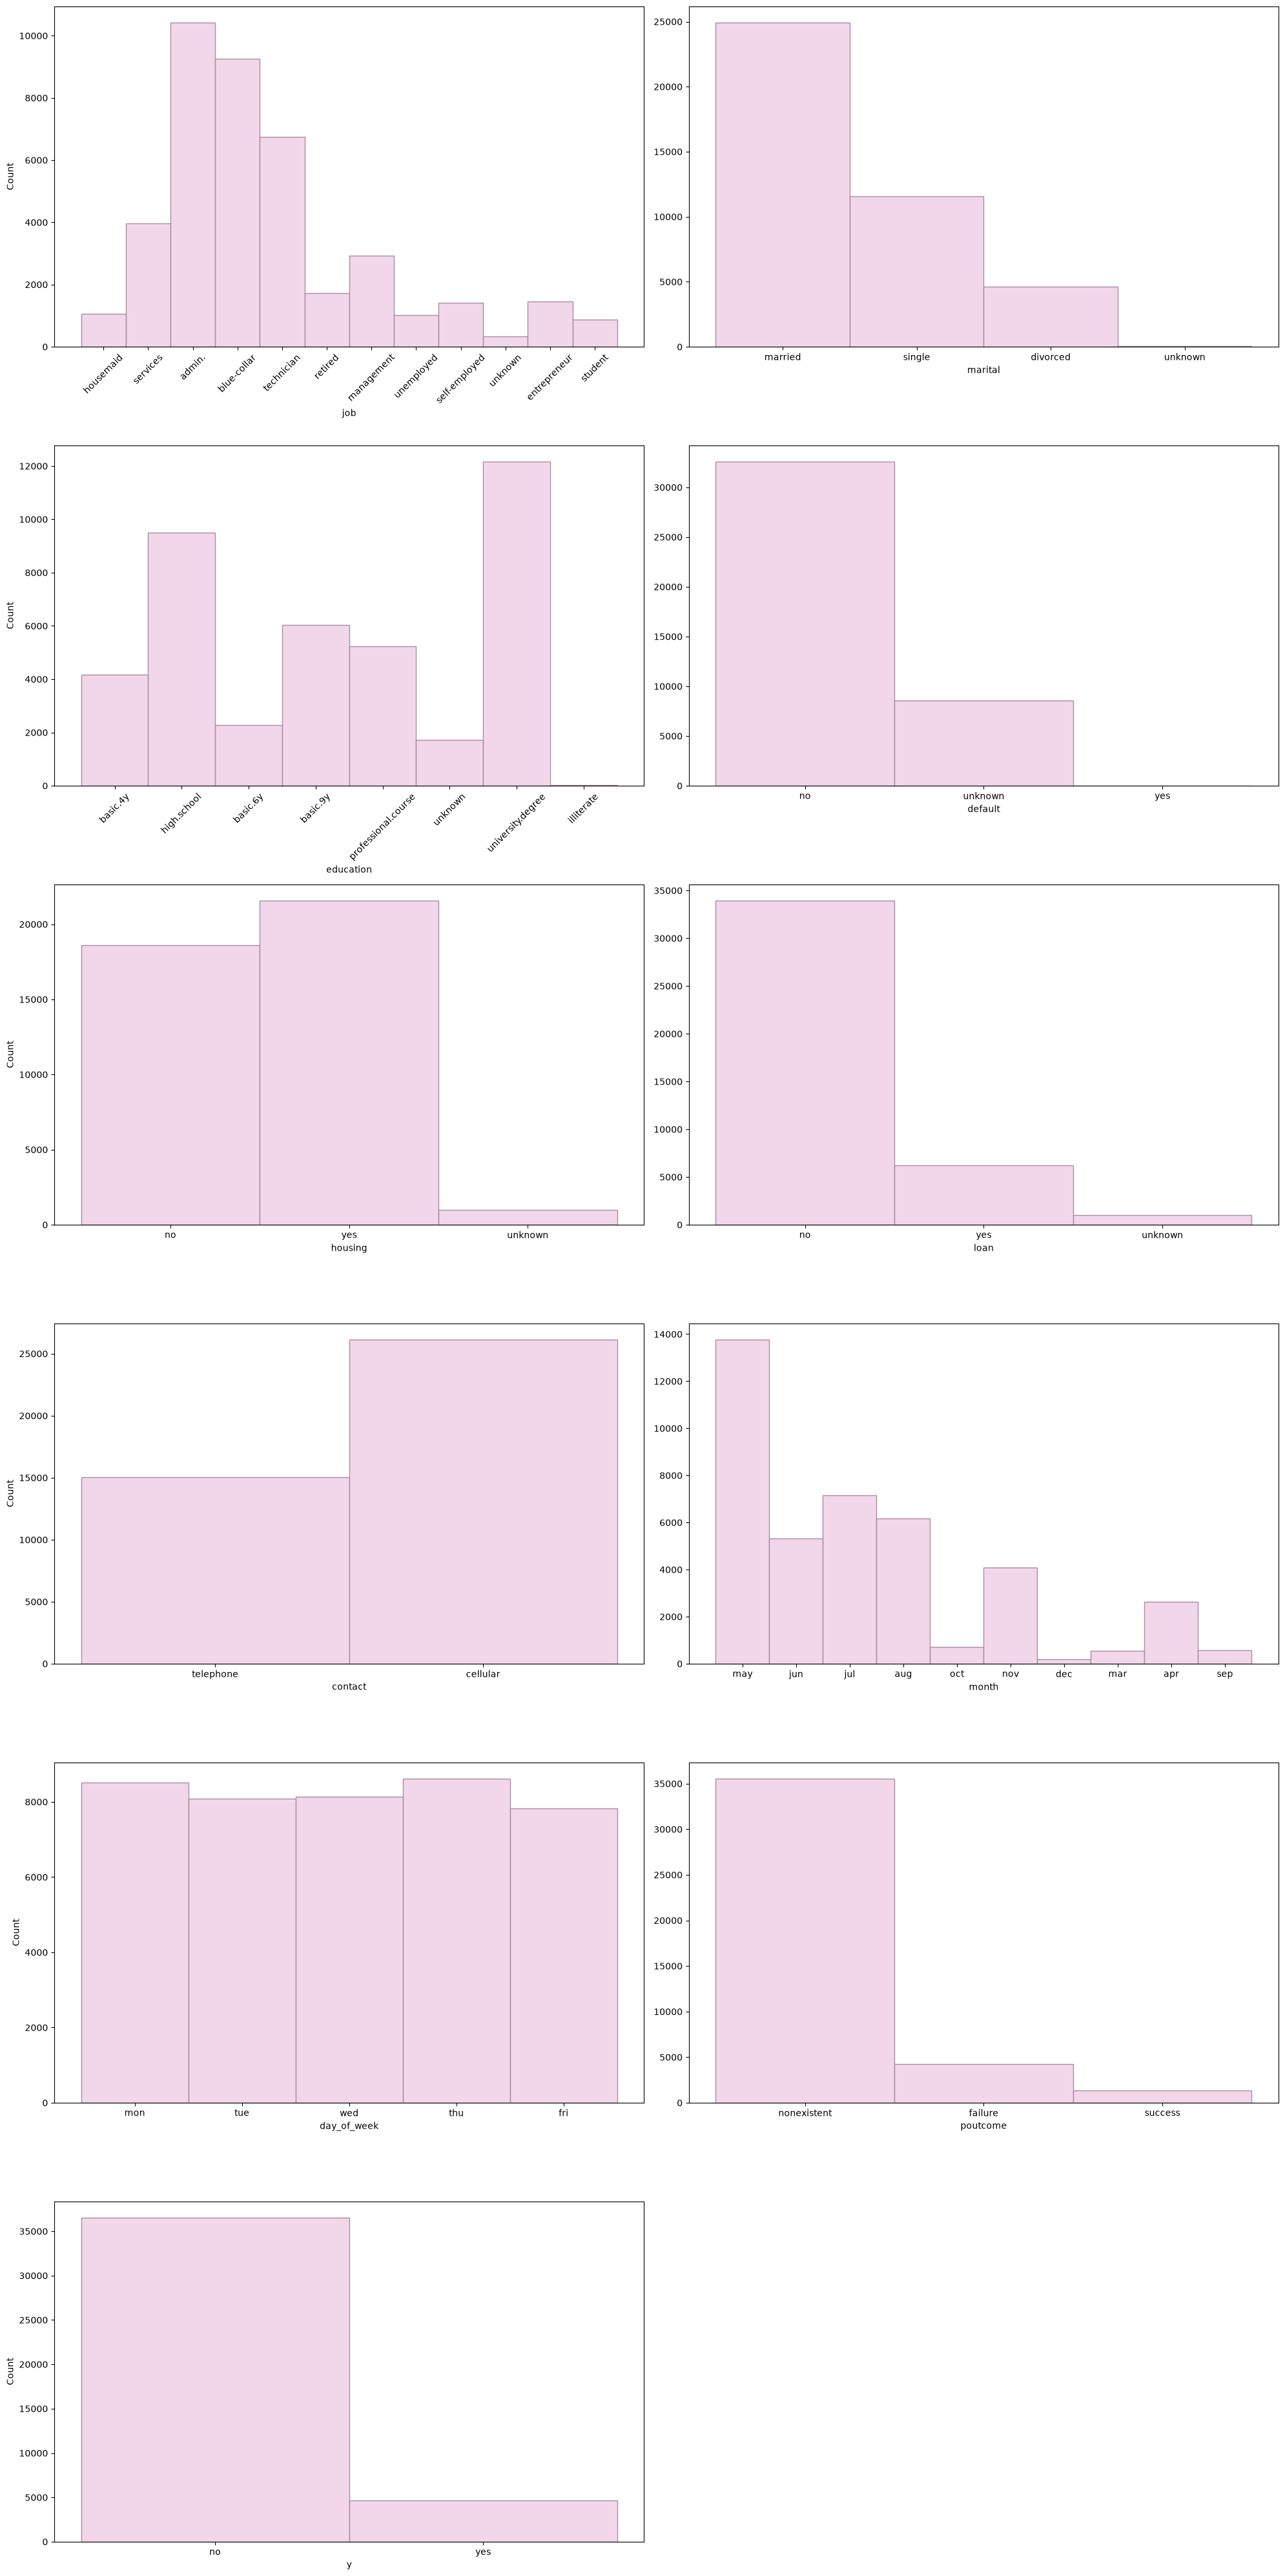

In [9]:
fig, axis = plt.subplots(6, 2, figsize = (20,40))

sns.histplot(ax = axis[0,0], data = df,x = 'job', color='#EDCAE2', edgecolor='#AB8CA3').tick_params(axis='x', rotation=45)
sns.histplot(ax = axis[0,1], data = df,x = 'marital', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[1,0], data = df,x = 'education', color='#EDCAE2', edgecolor='#AB8CA3')
axis[1,0].tick_params(axis='x', rotation=45)
sns.histplot(ax = axis[1,1], data = df,x = 'default', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[2,0], data = df,x = 'housing', color='#EDCAE2', edgecolor='#AB8CA3')
sns.histplot(ax = axis[2,1], data = df,x = 'loan', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[3,0], data = df,x = 'contact', color='#EDCAE2', edgecolor='#AB8CA3')
sns.histplot(ax = axis[3,1], data = df,x = 'month', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel= None)
sns.histplot(ax = axis[4,0], data = df,x = 'day_of_week', color='#EDCAE2', edgecolor='#AB8CA3')
sns.histplot(ax = axis[4,1], data = df,x = 'poutcome', color='#EDCAE2', edgecolor='#AB8CA3').set(ylabel = None)
sns.histplot(ax = axis[5,0], data = df,x = 'y', color='#EDCAE2', edgecolor='#AB8CA3')

fig.delaxes(axis[5,1])

plt.tight_layout()
plt.show()

Con las representaciones de cada variable, podemos determinar que:

- **'job'**: La mayoria de las personas tienen una ocupación de clasificacion "admin." (administrativos) con más de 10.000 observaciones y la siguiente mayoria son personas con una ocupación de clasificacion "blue_collar" (operarios) con más de 9.000 observaciones. Las clasificaciones de ocupaciones "housemaid" (dueñ@ de casa), "retired" (jubilado), "unemployed" (desempleado), "self-employed" (trabajadores por cuenta propia), "unknown" (desconocido), "entrepreneur" (emprendedor) y "student" (estudiante) tienen menos de 2.000 observaciones cada una. Más del 50% del universo de los datos corresponden a ocupaciones "admin." (administrativos), "blue_collar" (operarios) y "technician" (técnicos).

- **'marital'**: La clasificaión "married" (casad@) tiene la amplia mayoría de observaciones, teniendo más del 50% del universo de los datos. Y la minoría la tiene la clasificación "divorced" (divorciad@), con menos de 5.000 observaciones. Tenemos algunas observaciones para clasificación "unknown" (desconocido).

- **'education'**: Más del 50% de las personas tiene un nivel educativo "university.degree" (grado universitario), "high.school" (secundaria completa). 

- **'default'**: Más de el 70% no tiene créditos actualmente, y la cantidad de personas que si tiene es prácticamente de 0 observaciones. Teniendo una variabilidad casi nula. 

- **'housing'**: La distribución entre quienes si tienen un préstamo para una vivienda y quienes no, está bastante balanceado. Con una diferencia aproximada de 2.000 observaciones más para quienes si tienen uhn préstamo de vivienda.

- **'loan'**: La amplia mayoria la obtiene el "no", que representa los que no poseen un préstamo personal, con 33.000 observaciones aproximadamente, mientras el "si" tiene apenas 
3.000 observaciones.

- **'contact'**: La forma de contacto que predomina es "cellular", con lo que se puede inferir que tienen una buena accesibilidad a los clientes.

- **'month'**: Como último mes de contacto, se refleja una furte mayoría en el mes de mayo. Luego entre los meses junio, julio, agosto y noviembre, presentan un poco más de balance entre ellos. Los demás meses poseen mínimas observaciones.

- **'day_of_week'**: La distribución entre en qué día se contacto al cliente es bastante uniforme.

- **'poutcome'**: La amplia mayoría se la lleva la opción "nonexistent", lo que quiere decir que un gran porcentaje de los datos, son de personas que no las habían contactado en campañas anteriores.

- **'y'**: La relación entre quienes finalmente contratan un depósito a largo plazo y quienes no es inmensa. El "no" posee más de 35.000 observaciones, dejando muy desbalanceado el dataset.

#### Variables Numéricas

In [10]:
numericas = df.select_dtypes(exclude=['str']).columns.tolist()
numericas

['age',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed']

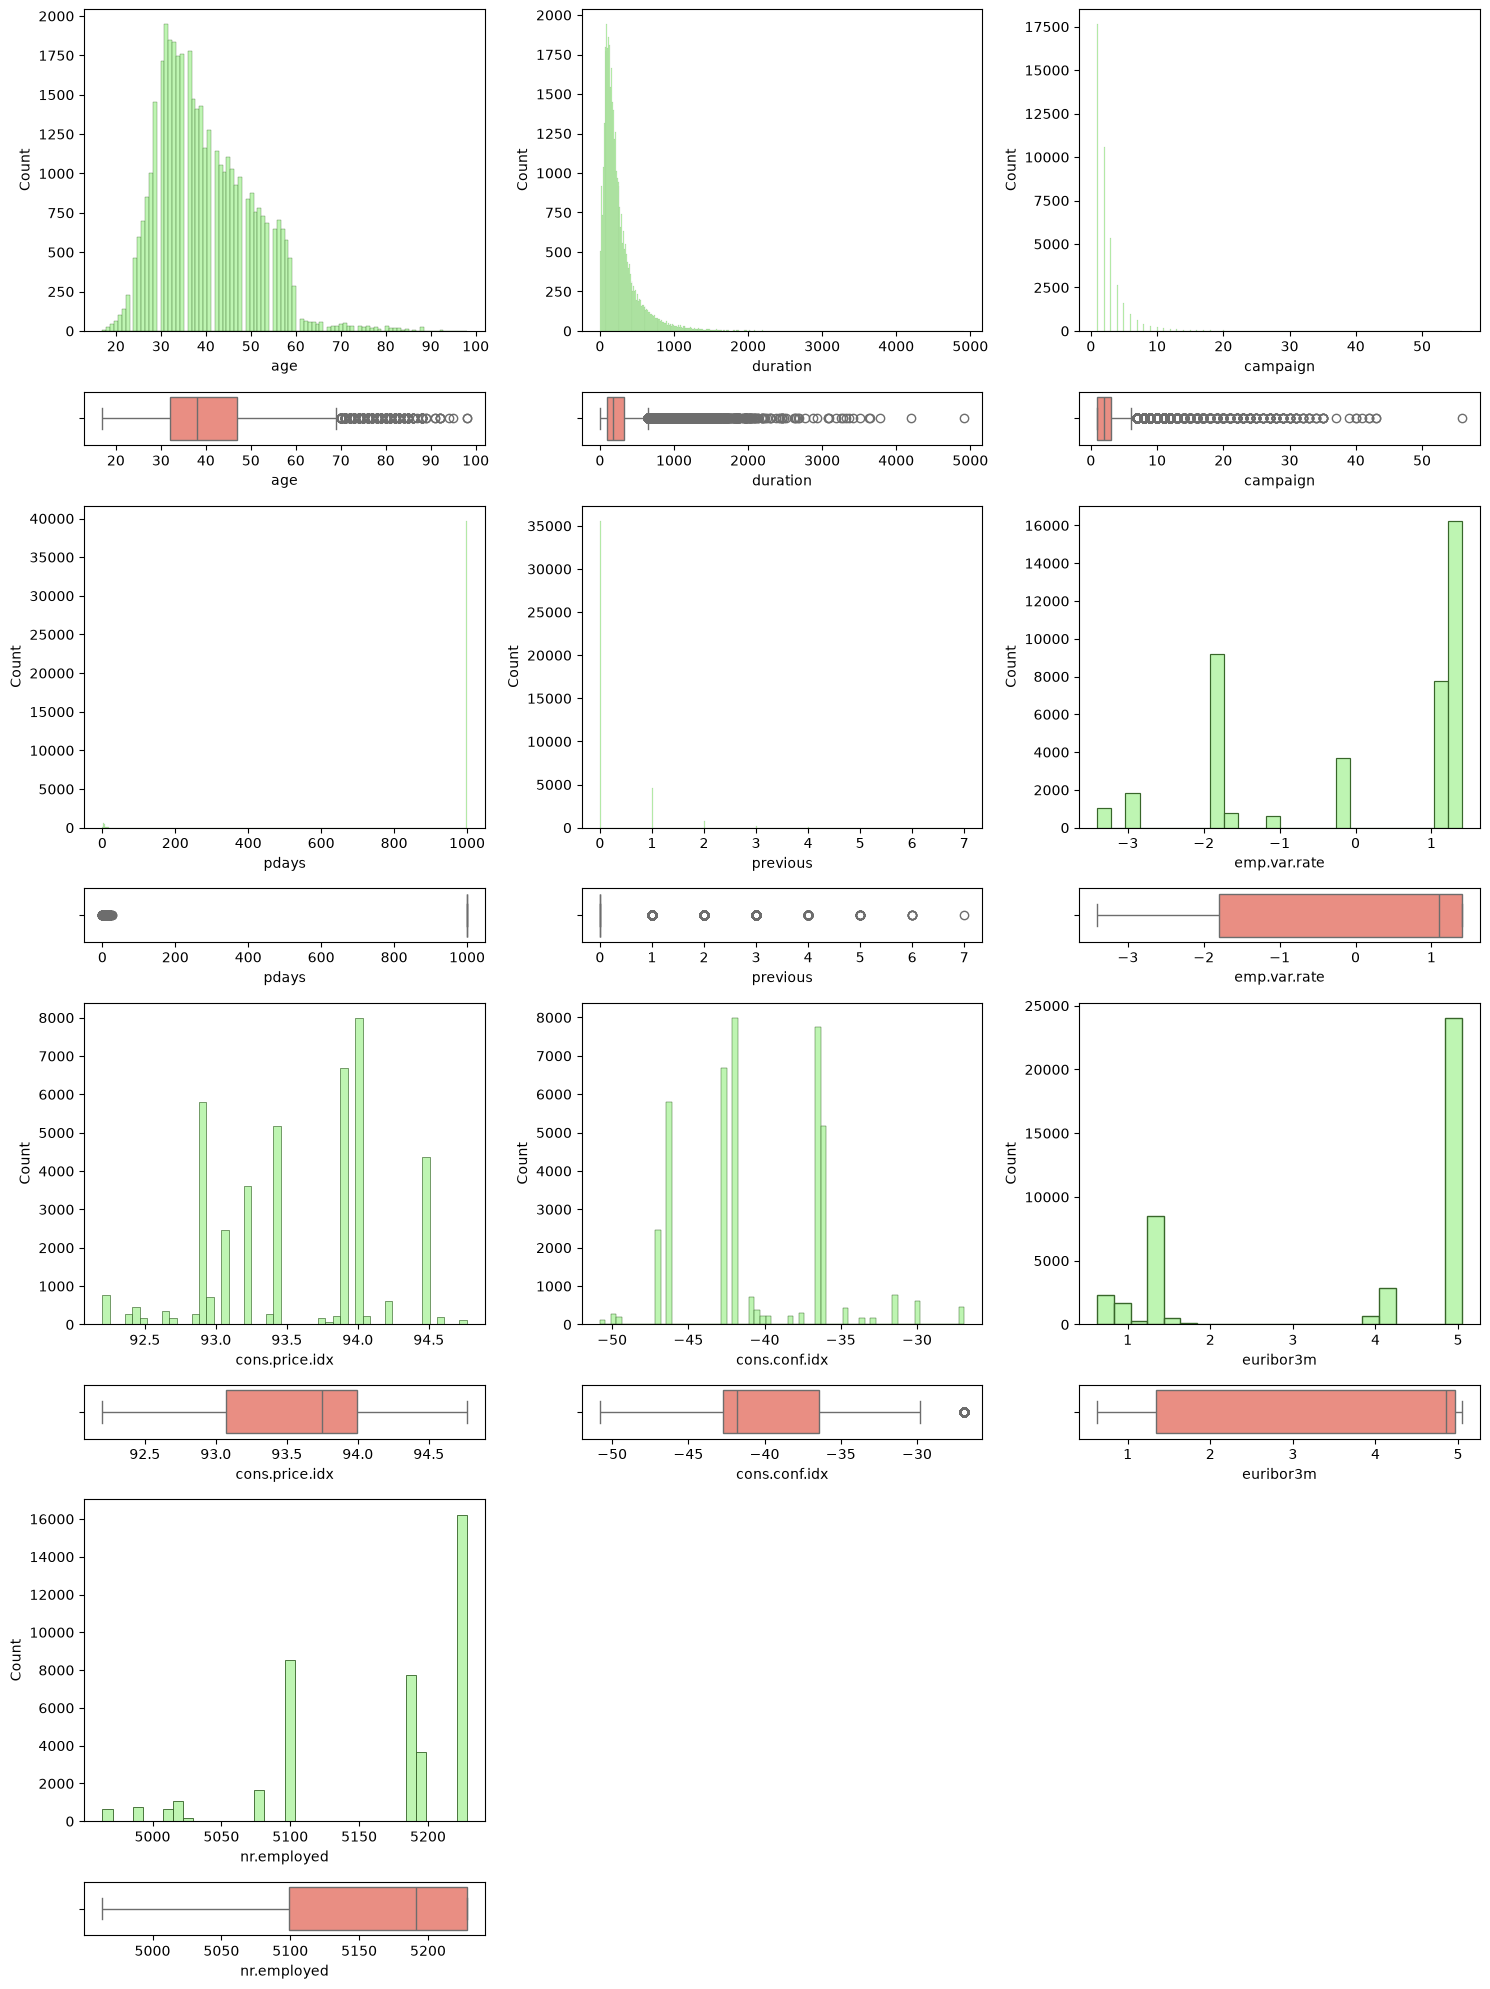

In [11]:
fig, axis = plt.subplots(8,3, figsize= (15,20),gridspec_kw= {"height_ratios":[6,1,6,1,6,1,6,1]})

sns.histplot(ax = axis[0,0], data = df, x = 'age', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[1,0], data = df, x = 'age', color='salmon')

sns.histplot(ax = axis[0,1], data = df, x = 'duration', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[1,1], data = df, x = 'duration', color='salmon')

sns.histplot(ax = axis[0,2], data = df, x = 'campaign', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[1,2], data = df, x = 'campaign', color='salmon')

sns.histplot(ax = axis[2,0], data = df, x = 'pdays', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[3,0], data = df, x = 'pdays', color='salmon')

sns.histplot(ax = axis[2,1], data = df, x = 'previous', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[3,1], data = df, x = 'previous', color='salmon')

sns.histplot(ax = axis[2,2], data = df, x = 'emp.var.rate', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[3,2], data = df, x = 'emp.var.rate', color='salmon')

sns.histplot(ax = axis[4,0], data = df, x = 'cons.price.idx', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[5,0], data = df, x = 'cons.price.idx', color='salmon')

sns.histplot(ax = axis[4,1], data = df, x = 'cons.conf.idx', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[5,1], data = df, x = 'cons.conf.idx', color='salmon')

sns.histplot(ax = axis[4,2], data = df, x = 'euribor3m', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[5,2], data = df, x = 'euribor3m', color='salmon')

sns.histplot(ax = axis[6,0], data = df, x = 'nr.employed', color='#A9F299', edgecolor='#38662A')
sns.boxplot(ax = axis[7,0], data = df, x = 'nr.employed', color='salmon')

fig.delaxes(axis[6,1])
fig.delaxes(axis[6,2])
fig.delaxes(axis[7,1])
fig.delaxes(axis[7,2])

plt.tight_layout()
plt.show()




Aanlizando los gráficos podemos inferir que:

- **'age'**: Los datos presentan una distribución sesgada hacia la derecha, y se concentran principalmente entre 30 y 50 años. Podemos observar varios valores atípicos sobre 70 años.

- **'duration'**: Los datos muestran que la mayoría de las llamadas duran aproximadamente menos de 200 segundos, y a la vez tenemos muchísimos valores atípicos sobre 700 segundos aprox.

- **'campaign'**: La gran mayoría de los clientes han recibido 2 llamados durante la campaña y podemos observar algunos valores atípicos sobre 6 llamados, incluso un valor atípico mayor a 50, lo que podría ser un error.

- **'pdays'**: Casi la totalidad de los datos estan situados en el valor 999, que puedo entender que implica que no fueron contactados anteriormente, y tenemos uns pocos valores atípicos que nos muestra la cantidad de días que han pasado desde el contacto con algunos clientes, pero debido a lo pocos clientes que son, la variable no aporta mucha relevancia.

- **'previous'**: Nuevamente los datos nos muestran que la amplia mayoría de clientes no ha sido contactado en campañas anteriores, teniendo apenas 5.000(aprox) clientes que si lo han sido. Con esto podemos inferir que esta campaña cuenta con una mayoría amplia de clientes nuevos.

- **'emp.var.rate'**: Podemos observar dos bloques marcados, uno con valores positivos entre 1 y 2, y otro con valores negativos poquito mayores a -2. No tenemos valores atípicos.

- **'cons.price.idx'**: Los datos no presentan una distribución normal y se comporta de forma multimodal. No se observan valores atípicos.

- **'cons.conf.idx'**: Los datos no presentan una distribución normal y se comporta de forma multimodal. Solamente tenemos datos negativos, concentándose entre -45 y -35. Mínimos valores atípicos.

- **'euribor3m'**: Gran mayoría concentrada en valores aproximadamente a 5 sin valores atípicos.

- **'nr.employed'**: Los datos se concentran en valores entre 5100 y 5250 sin balores atípicos.

### Paso 4 EDA: Análisis de variables multivariante

#### Numérico-numérico

Primero transformaremos a numérica nuestra variable objetivo ***'y'***



In [12]:
df['y'] = df['y'].map({'no': 0, 'yes': 1})

print(df['y'].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


Ahora analizaremos nuestras variables numéricas con respecto a nuestra variable objetivo.

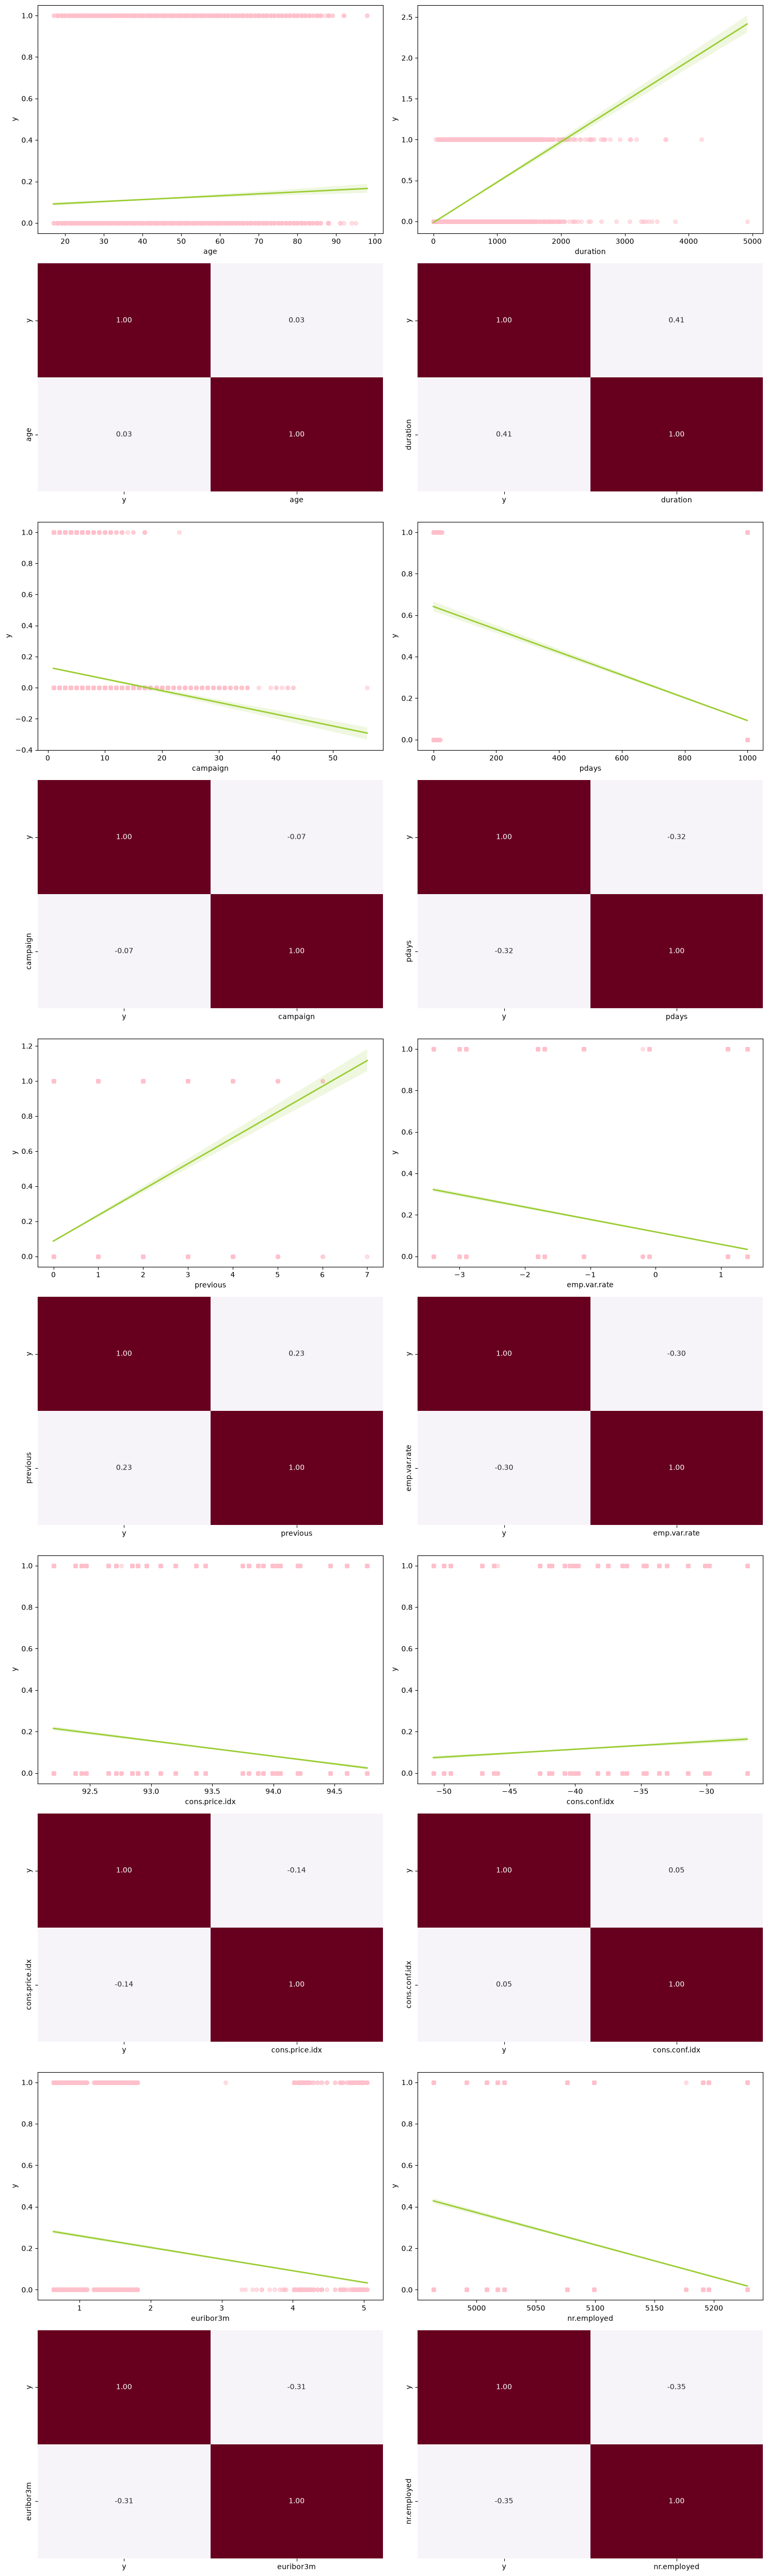

In [13]:
fig, axis = plt.subplots(10, 2, figsize = (15,50))

sns.regplot(ax = axis[0, 0], data = df, x = "age", y = "y", scatter_kws = {'s':30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "age"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 0],cbar = False, cmap='PuRd')
sns.regplot(ax = axis[0, 1], data = df, x = "duration", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "duration"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[2, 0], data = df, x = "campaign", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "campaign"]].corr(), annot = True, fmt = ".2f", ax = axis[3, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[2,1], data = df, x = "pdays", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "pdays"]].corr(), annot = True, fmt = ".2f", ax = axis[3, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[4,0], data = df, x = "previous", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "previous"]].corr(), annot = True, fmt = ".2f", ax = axis[5, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[4,1], data = df, x = "emp.var.rate", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "emp.var.rate"]].corr(), annot = True, fmt = ".2f", ax = axis[5, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[6,0], data = df, x = "cons.price.idx", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "cons.price.idx"]].corr(), annot = True, fmt = ".2f", ax = axis[7, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[6,1], data = df, x = "cons.conf.idx", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "cons.conf.idx"]].corr(), annot = True, fmt = ".2f", ax = axis[7, 1], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[8,0], data = df, x = "euribor3m", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "euribor3m"]].corr(), annot = True, fmt = ".2f", ax = axis[9, 0], cbar = False, cmap='PuRd')
sns.regplot(ax = axis[8,1], data = df, x = "nr.employed", y = "y", scatter_kws = {'s': 30 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["y", "nr.employed"]].corr(), annot = True, fmt = ".2f", ax = axis[9, 1], cbar = False, cmap='PuRd')

plt.tight_layout()

plt.show()

Conclusiones con respecto al gráfico anterior:

- **'age'**: La pendiente es practicamente plana y su correlación con nuestra variable objetivo es muy débil.

- **'duration'**: Pendiente fuertemente ascendente y alta correlación (0,41), por lo que a mayor duraión de la llamada, mayor probabilidad de que contrate un depósito a plazo.

- **'campaign'**: Pendiente descendente y una correlación debilmente negativa por lo que, realizar demasiadas llamadas durante una misma campaña disminuye la tasa de éxito.

- **'pdays'**: Pendiente altamente descendente debido a que la mayoría de los datos se concentran en el valor 999. Su correlación es negativa (-0,32).

- **'previous'**: Pendiente ascendente marcada y correlación alto, o sea, nos muestra el número de contactos en campañas anteriores es un predictor favorable.

- **'emp.var.rate'**: Pendiente descendente marcada y una correlación negativa importante , lo que nos indica que cuando hay alta tasa de variación de empleo, la disposición a contratar baja.

- **'cons.price.idx'**: Pendiente descendente y correlación negativa leve, con lo que podemos inferir que cuando la inflación es más alta, disminuye levemente la probabilidad de contratar.

- **'cons.conf.idx'**: Pendiente practicamente plana, con una correlación positiva muy débil, o sea, un impacto mínimo sobre nuestra variable objetivo.

- **'euribor3m'**: Pendiente fuertemente descendente y correlación alta negativa, indicándonos que cuando la tasa Euribor es alta, reduce significativamente las probabilidades de contratar.

- **'nr.employed'**: Pendiente fuertemente descendente y correlación alta negativa con un comportamiento muy similar a la variable anterior, mostrándonos una alta multicolinealidad con ésta misma.

O sea, las variables con correlaciones más fuertes son: **'duration'**, **'pdays'**, **'previous'**, **'emp.var.rate'**, **'euribor3m'** y **'nr.employed'**.

#### Categórico-Categórico




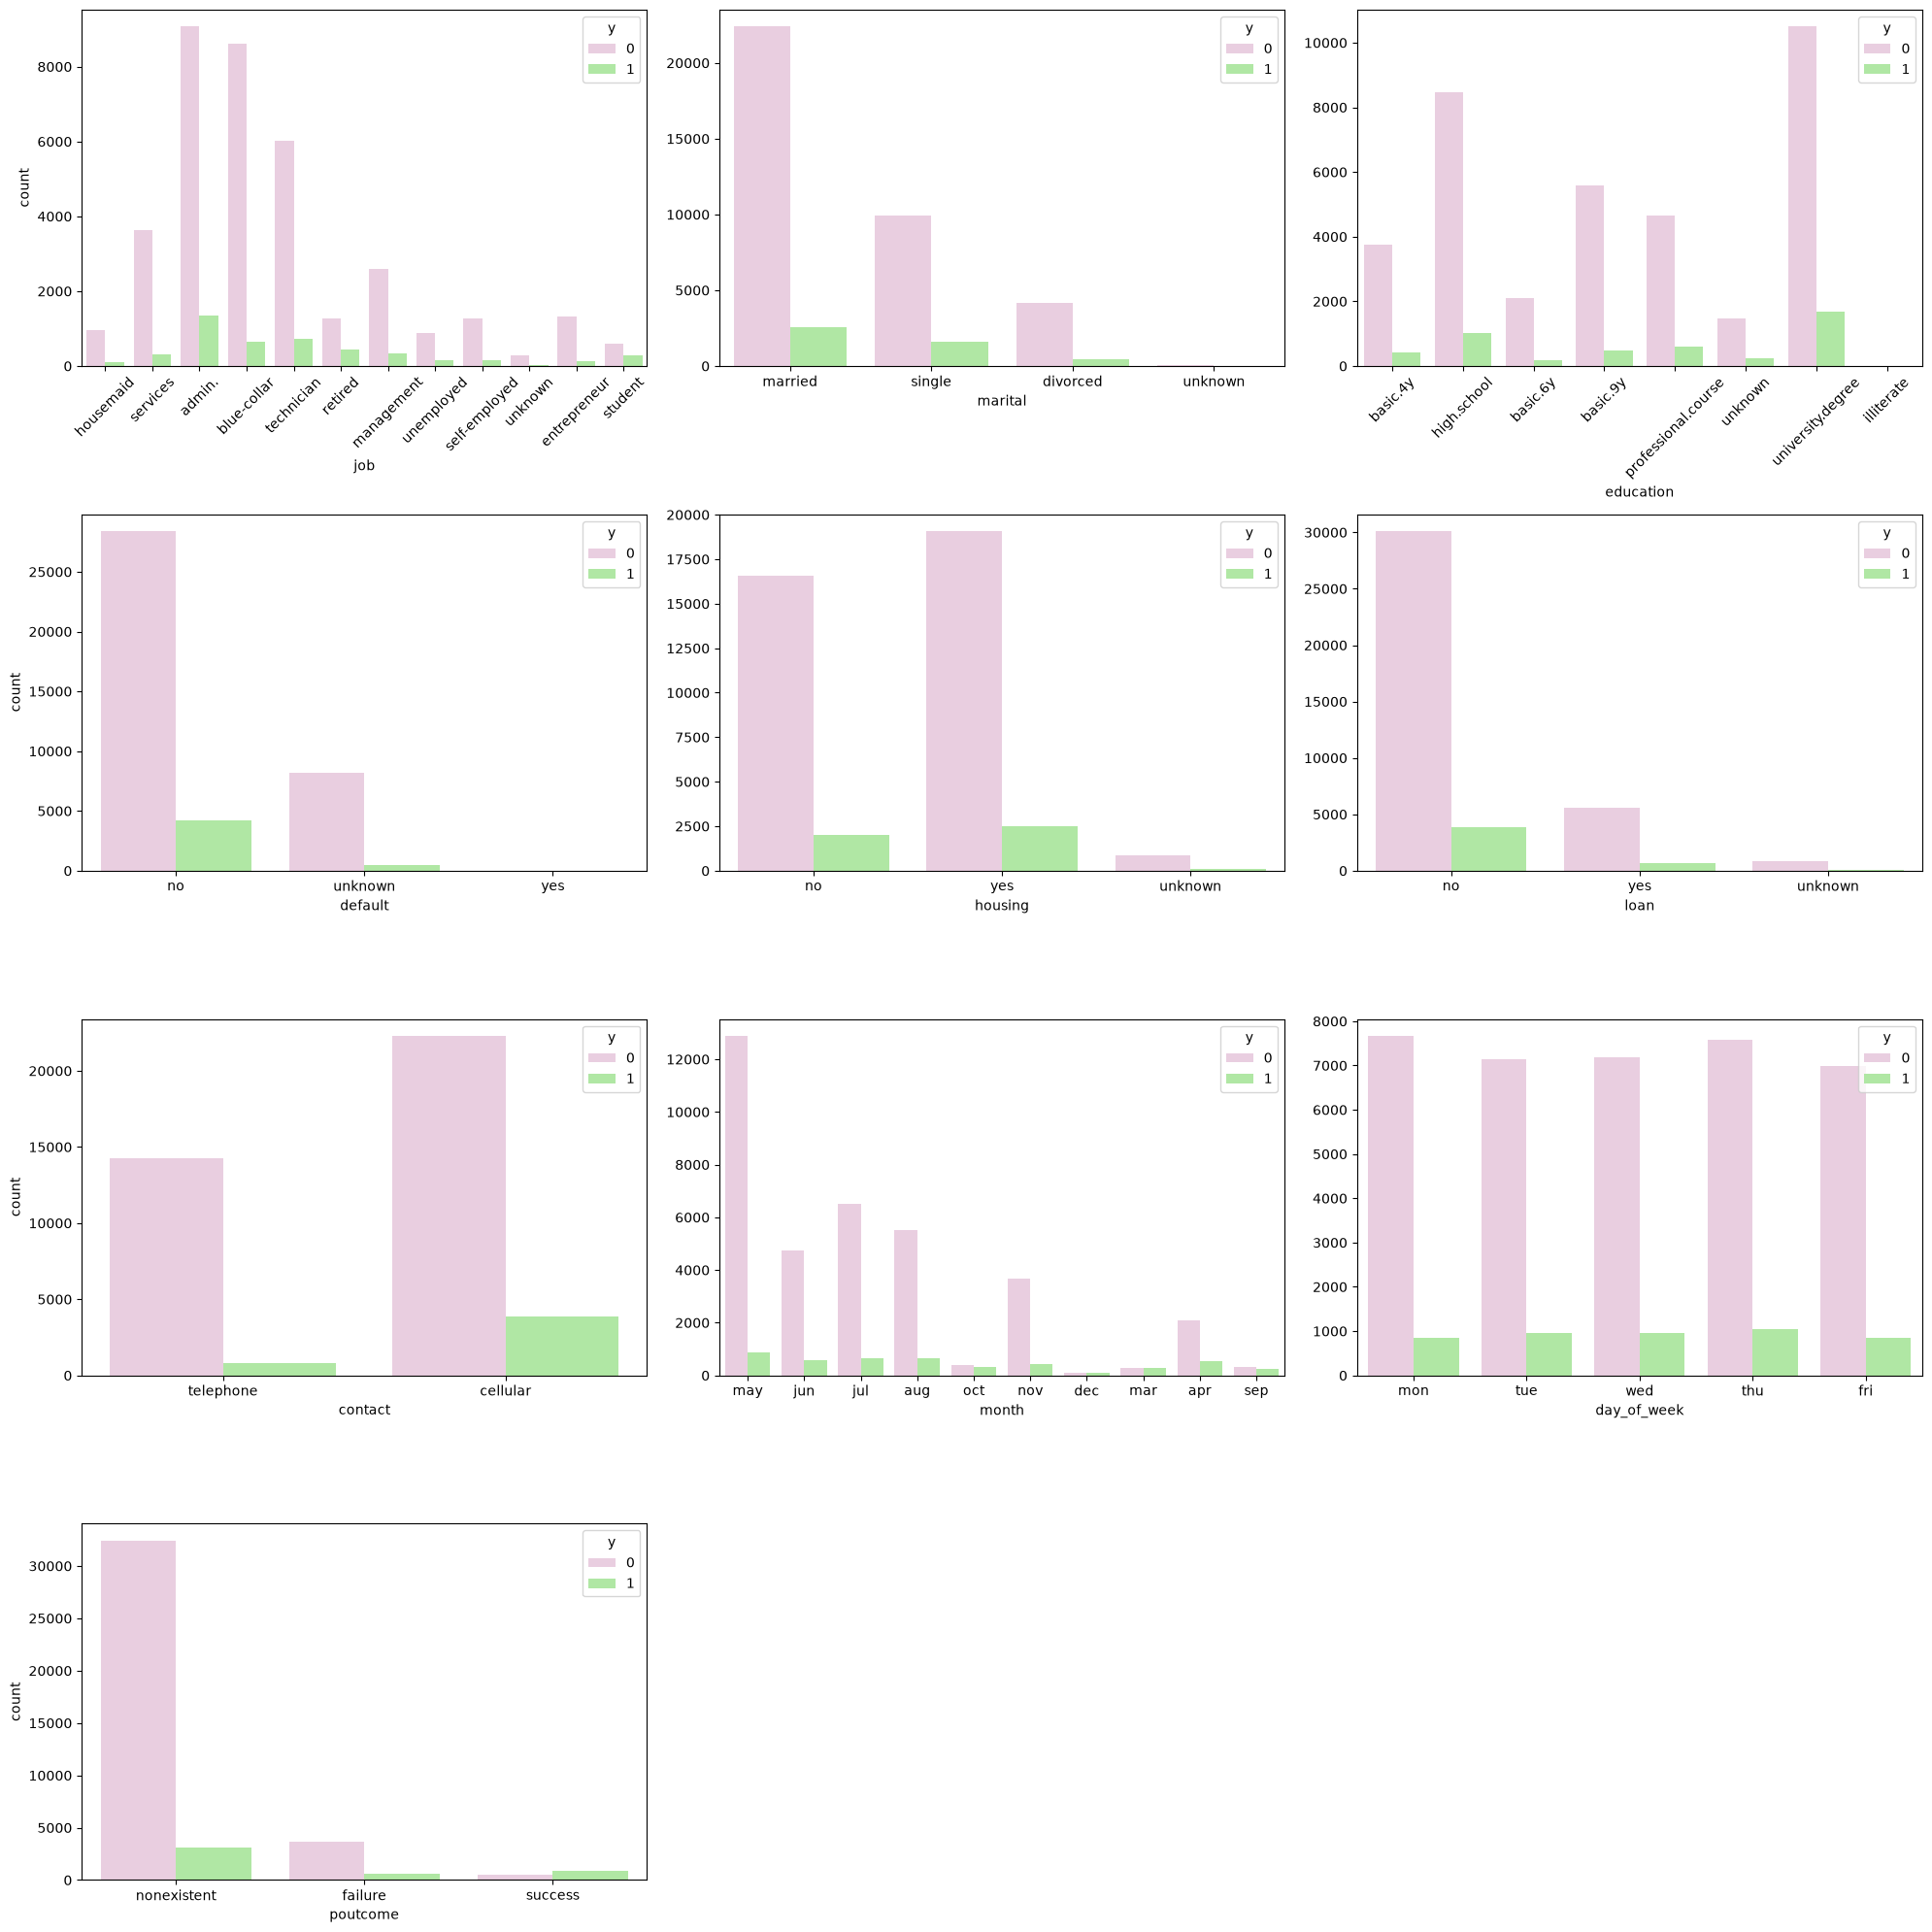

In [14]:
fig, axis = plt.subplots(4, 3, figsize = (20,20))

colores_hue = ['#EDCAE2','#A9F299']

sns.countplot(ax = axis[0, 0], data = df, x = "job", hue = "y", palette = colores_hue).tick_params(axis='x', rotation=45)
sns.countplot(ax = axis[0, 1], data = df, x = "marital", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[0, 2], data = df, x = "education", hue = "y", palette = colores_hue).set(ylabel = None)
axis[0, 2].tick_params(axis='x', rotation=45)
sns.countplot(ax = axis[1, 0], data = df, x = "default", hue = "y", palette = colores_hue)
sns.countplot(ax = axis[1, 1], data = df, x = "housing", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[1, 2], data = df, x = "loan", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[2, 0], data = df, x = "contact", hue = "y", palette = colores_hue)
sns.countplot(ax = axis[2, 1], data = df, x = "month", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[2, 2], data = df, x = "day_of_week", hue = "y", palette = colores_hue).set(ylabel = None)
sns.countplot(ax = axis[3, 0], data = df, x = "poutcome", hue = "y", palette = colores_hue)

fig.delaxes(axis[3, 1])
fig.delaxes(axis[3, 2])

plt.tight_layout()

plt.show()

Analizando los gráficos anteriores concluimos que:

- **'job'**: "admin." y "technician" aportan el mayor volumen de conversiones, sin embargo clasificaciones más pequeñas como "student" y "retired" muestran una tasa de conversión significativamente más alta en relación con su volumen total.

- **'marital'**: Si bien la mayoria de clientes que contratan un depósito a plazo son casados("married"), tiene mayor tasa de conversión los clientes que son solteros("single").

- **'education'**: Los clientes que más tendencia tienen a contratar, son clientes con estudios universitarios("university.degree"), seguido por los que tienen secundaria completa("high.school"), por ende, a mayor estudios, mayor conversión.

- **'default'**: La cantidad de clientes que tienen crédito actualmente es casi nula, por lo que las conversiones suelen se casi todas en los clientes que no tienen credito.

- **'housing'**: La proporción de conversión entre quienes tienen un préstamo hipotecario y quienes no lo tienen, es muy similar entre ellos, por lo que no impacta en la decisión del cliente sobre si contrata, o no, un depósito.

- **'loan'**: Quienes no tienen un préstamo personal concentran casi todas las conversiones. Esta variable no muestra mucha capacidad de discriminación por si sola ante si alguien contrata, o no, un depósito, aunque los datos nos muestran que si no tiene un préstamo personal, facilita que contrate un depósito.

- **'contact'**: El contacto vía teléfono celular ("cellular") es significativamente más efectivo que vía teléfono fijo ("telephone"), obteniendo una mayor tasa de éxito y una mejor proporción de conversiones.

- **'month'**: La campaña tiene su mayor concentración en mayo ("may"), pero la tasa de conversión en este mes es muy baja en comparación con la cantidad de rechazos. Los meses con baja cantidad de llamadas como marzo ("mar"), septiembre ("sep"), octubre ("oct") y diciembre ("dec") muestran tasas de conversión muy altas.

- **'day_of_week'**: El volumen de contactos y la tasa de conversión se mantienen de forma bastante homogénea a lo largo de todos los días hábiles de la semana (de lunes a viernes).

Existe un fuerte desbalance de clases en la mayoría de las variables. La gran mayoría de los clientes contactados rechazan suscribirse a productos bancarios, mientras que solo una pequeña cantidad acepta.


**Combinaciones de la clase con varias predictoras**

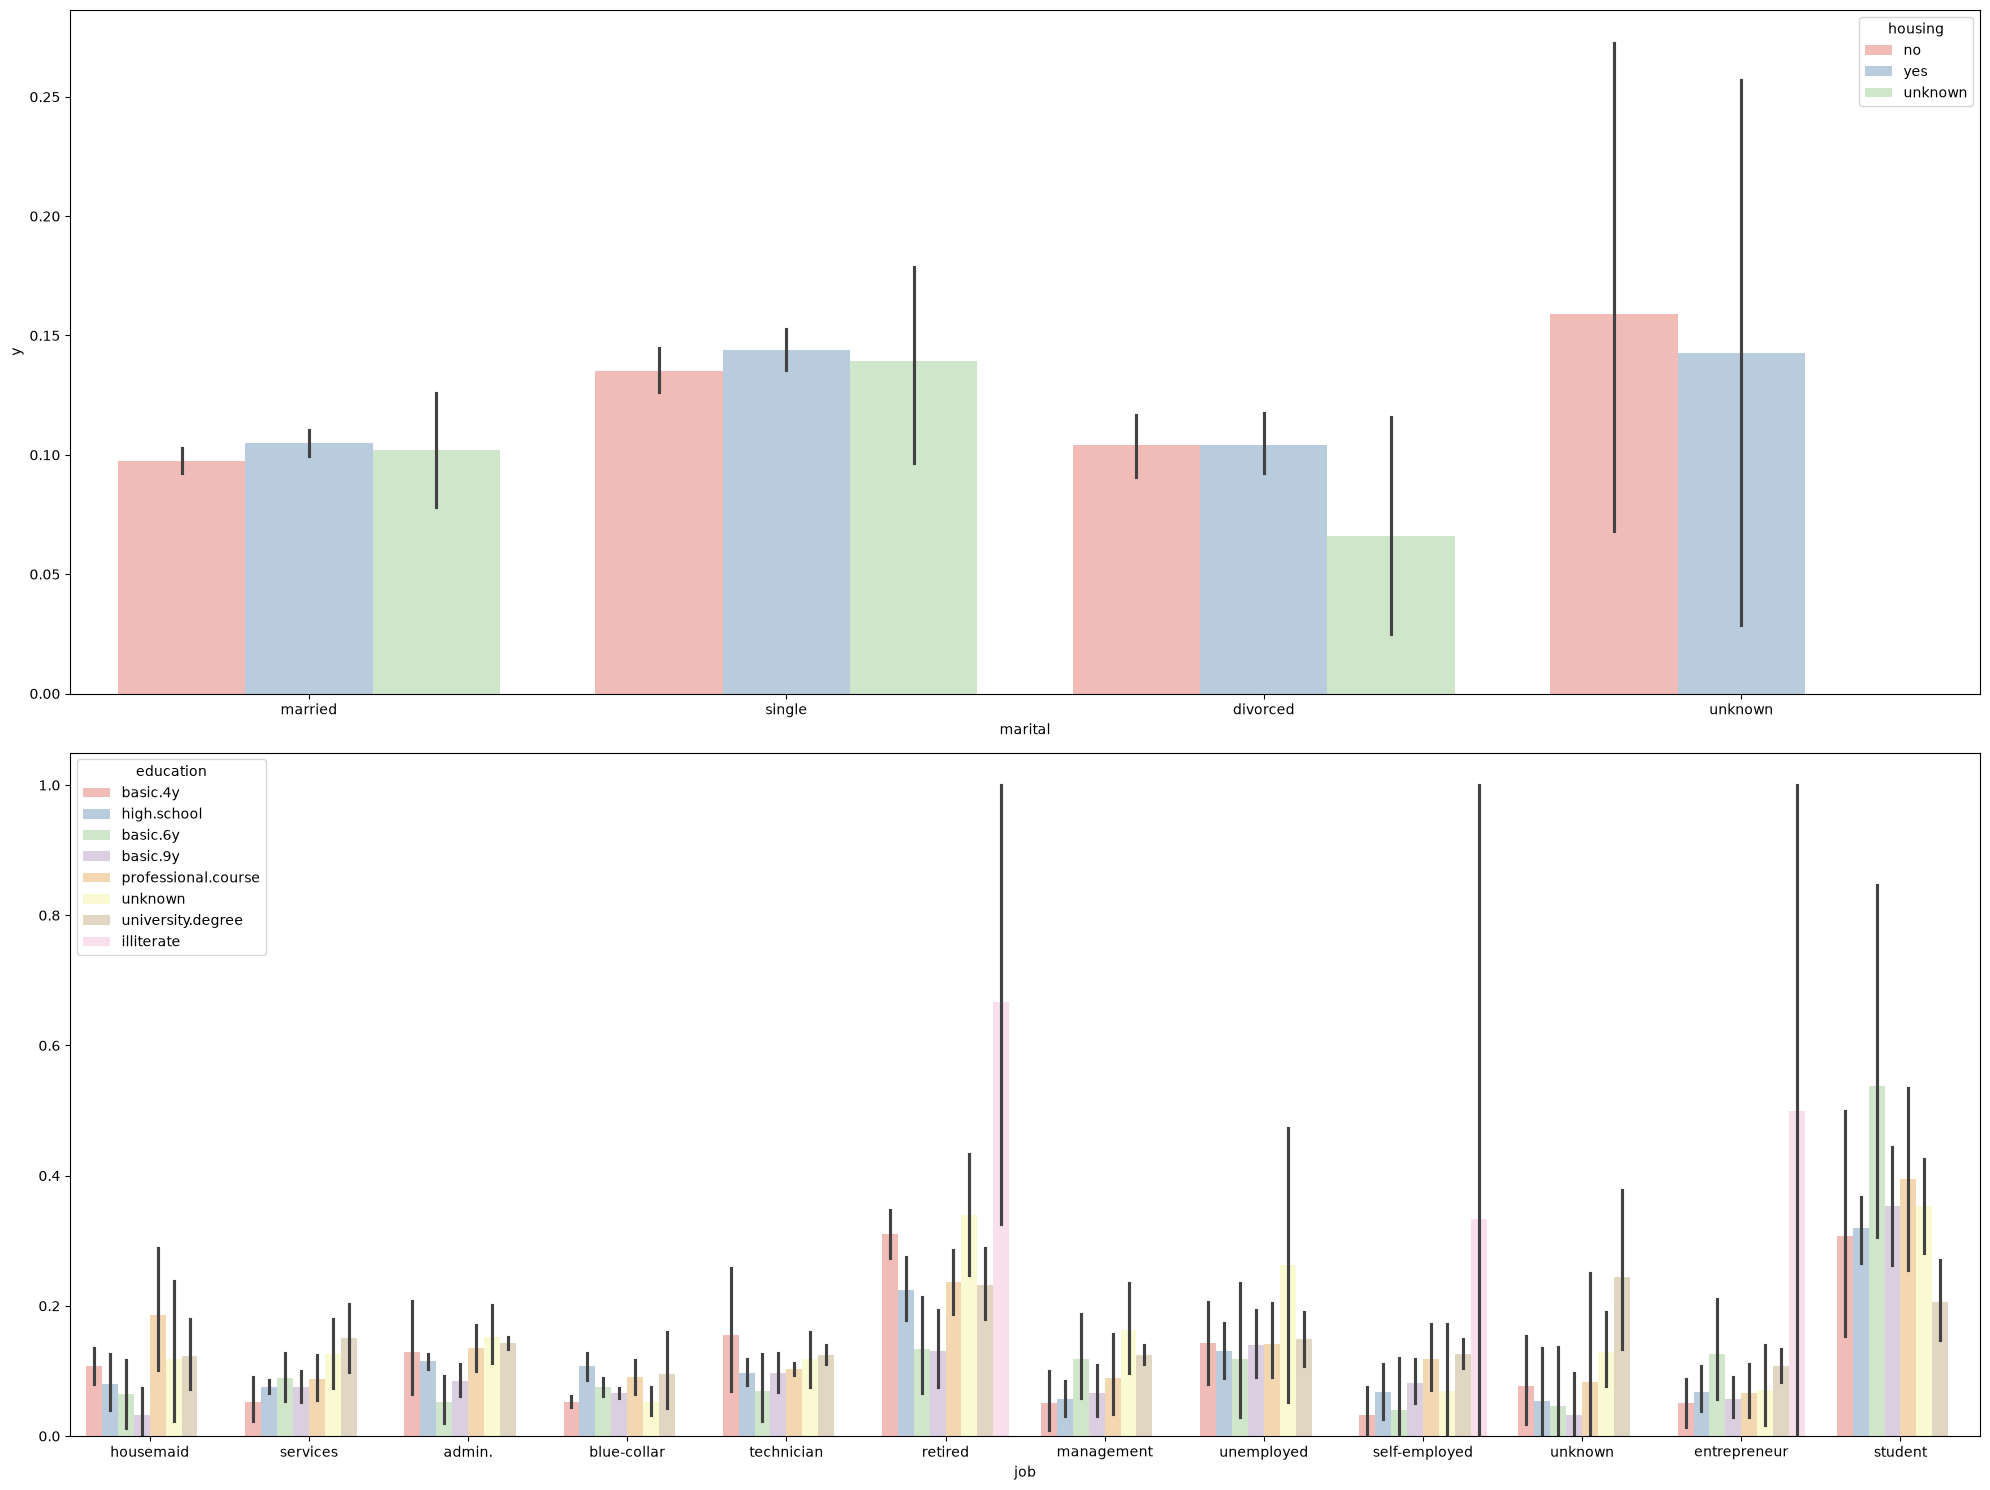

In [15]:

fig, axis = plt.subplots(2, 1, figsize = (20, 15))

sns.barplot(ax = axis[0], data = df, x = 'marital', y = 'y', hue = 'housing', palette = 'Pastel1')
sns.barplot(ax = axis[1], data = df, x = 'job', y = 'y', hue = 'education', palette = 'Pastel1').set(ylabel = None)

plt.tight_layout()
plt.show()


In [16]:
# job vs y
tabla_job = pd.crosstab(df["job"], df["y"])
print("Trabajo vs Éxito")
print(tabla_job, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_job)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

# Interpretación
if p < 0.05:
    print("Existe una relación significativa entre trabajo y éxito.")
    print("La tabla muestra que proporcionalmente hay más éxito en ciertos trabajos que en otros.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# marital vs y
tabla_marital = pd.crosstab(df["marital"], df["y"])
print("Estado civil vs Éxito")
print(tabla_marital, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_marital)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El estado civil está asociado con la probabilidad de éxito.")
    print("Las personas en ciertos estados civiles tienen más posibilidades de éxito que en otros.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# education vs y
tabla_education = pd.crosstab(df["education"], df["y"])
print("Educación vs Éxito")
print(tabla_education, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_education)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("La educación tiene cierta relación con la probabilidad de éxito.")
    print("Las personas con cierto nivel de educación tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# default vs y
tabla_default = pd.crosstab(df["default"], df["y"])
print("Posee Crédito vs Éxito")
print(tabla_default, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_default)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("Si alguien tiene crédito, está asociado con la probabilidad de éxito.")
    print("Las personas con crédito tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# housing vs y
tabla_housing = pd.crosstab(df["housing"], df["y"])
print("Crédito de Vivienda vs Éxito")
print(tabla_housing, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_housing)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El crédito de vivienda está asociado con la probabilidad de éxito.")
    print("Las personas con crédito de vivienda tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# loan vs y
tabla_loan = pd.crosstab(df["loan"], df["y"])
print("Préstamo Personal vs Éxito")
print(tabla_loan, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_loan)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El préstamo personal está asociado con la probabilidad de éxito.")
    print("Las personas con préstamo personal tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# contact vs y
tabla_contact = pd.crosstab(df["contact"], df["y"])
print("Contacto vs Éxito")
print(tabla_contact, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_contact)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El tipo decontacto está asociado con la probabilidad de éxito.")
    print("Las personas con cierto tipo de contacto tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# month vs y
tabla_month = pd.crosstab(df["month"], df["y"])
print("Mes de contacto vs Éxito")
print(tabla_month, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_month)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El mes de contacto está asociado con la probabilidad de éxito.")
    print("Las personas contactadas en ciertos meses tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# day_of_week vs y
tabla_day_of_week = pd.crosstab(df["day_of_week"], df["y"])
print("Día de la semana de contacto vs Éxito")
print(tabla_day_of_week, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_day_of_week)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El día de la semana de contacto está asociado con la probabilidad de éxito.")
    print("Las personas contactadas en ciertos días tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")


# poutcome vs y
tabla_poutcome = pd.crosstab(df["poutcome"], df["y"])
print("Resultado de la campaña previa vs Éxito")
print(tabla_poutcome, "\n")

chi2, p, dof, expected = chi2_contingency(tabla_poutcome)
print(f"Chi2 = {chi2:.2f}, p-value = {p:.4f}\n")

if p < 0.05:
    print("El resultado de la campaña previa está asociado con la probabilidad de éxito.")
    print("Las personas con cierto resultado tienen mayor proporción de éxito que otras.\n")
else:
    print("No se observa una relación estadísticamente significativa.\n")

Trabajo vs Éxito
y                 0     1
job                      
admin.         9068  1351
blue-collar    8615   638
entrepreneur   1332   124
housemaid       954   106
management     2596   328
retired        1284   434
self-employed  1272   149
services       3644   323
student         600   275
technician     6009   730
unemployed      870   144
unknown         293    37 

Chi2 = 961.74, p-value = 0.0000

Existe una relación significativa entre trabajo y éxito.
La tabla muestra que proporcionalmente hay más éxito en ciertos trabajos que en otros.

Estado civil vs Éxito
y             0     1
marital              
divorced   4135   476
married   22390  2531
single     9944  1620
unknown      68    12 

Chi2 = 122.96, p-value = 0.0000

El estado civil está asociado con la probabilidad de éxito.
Las personas en ciertos estados civiles tienen más posibilidades de éxito que en otros.

Educación vs Éxito
y                        0     1
education                       
basic.4y        

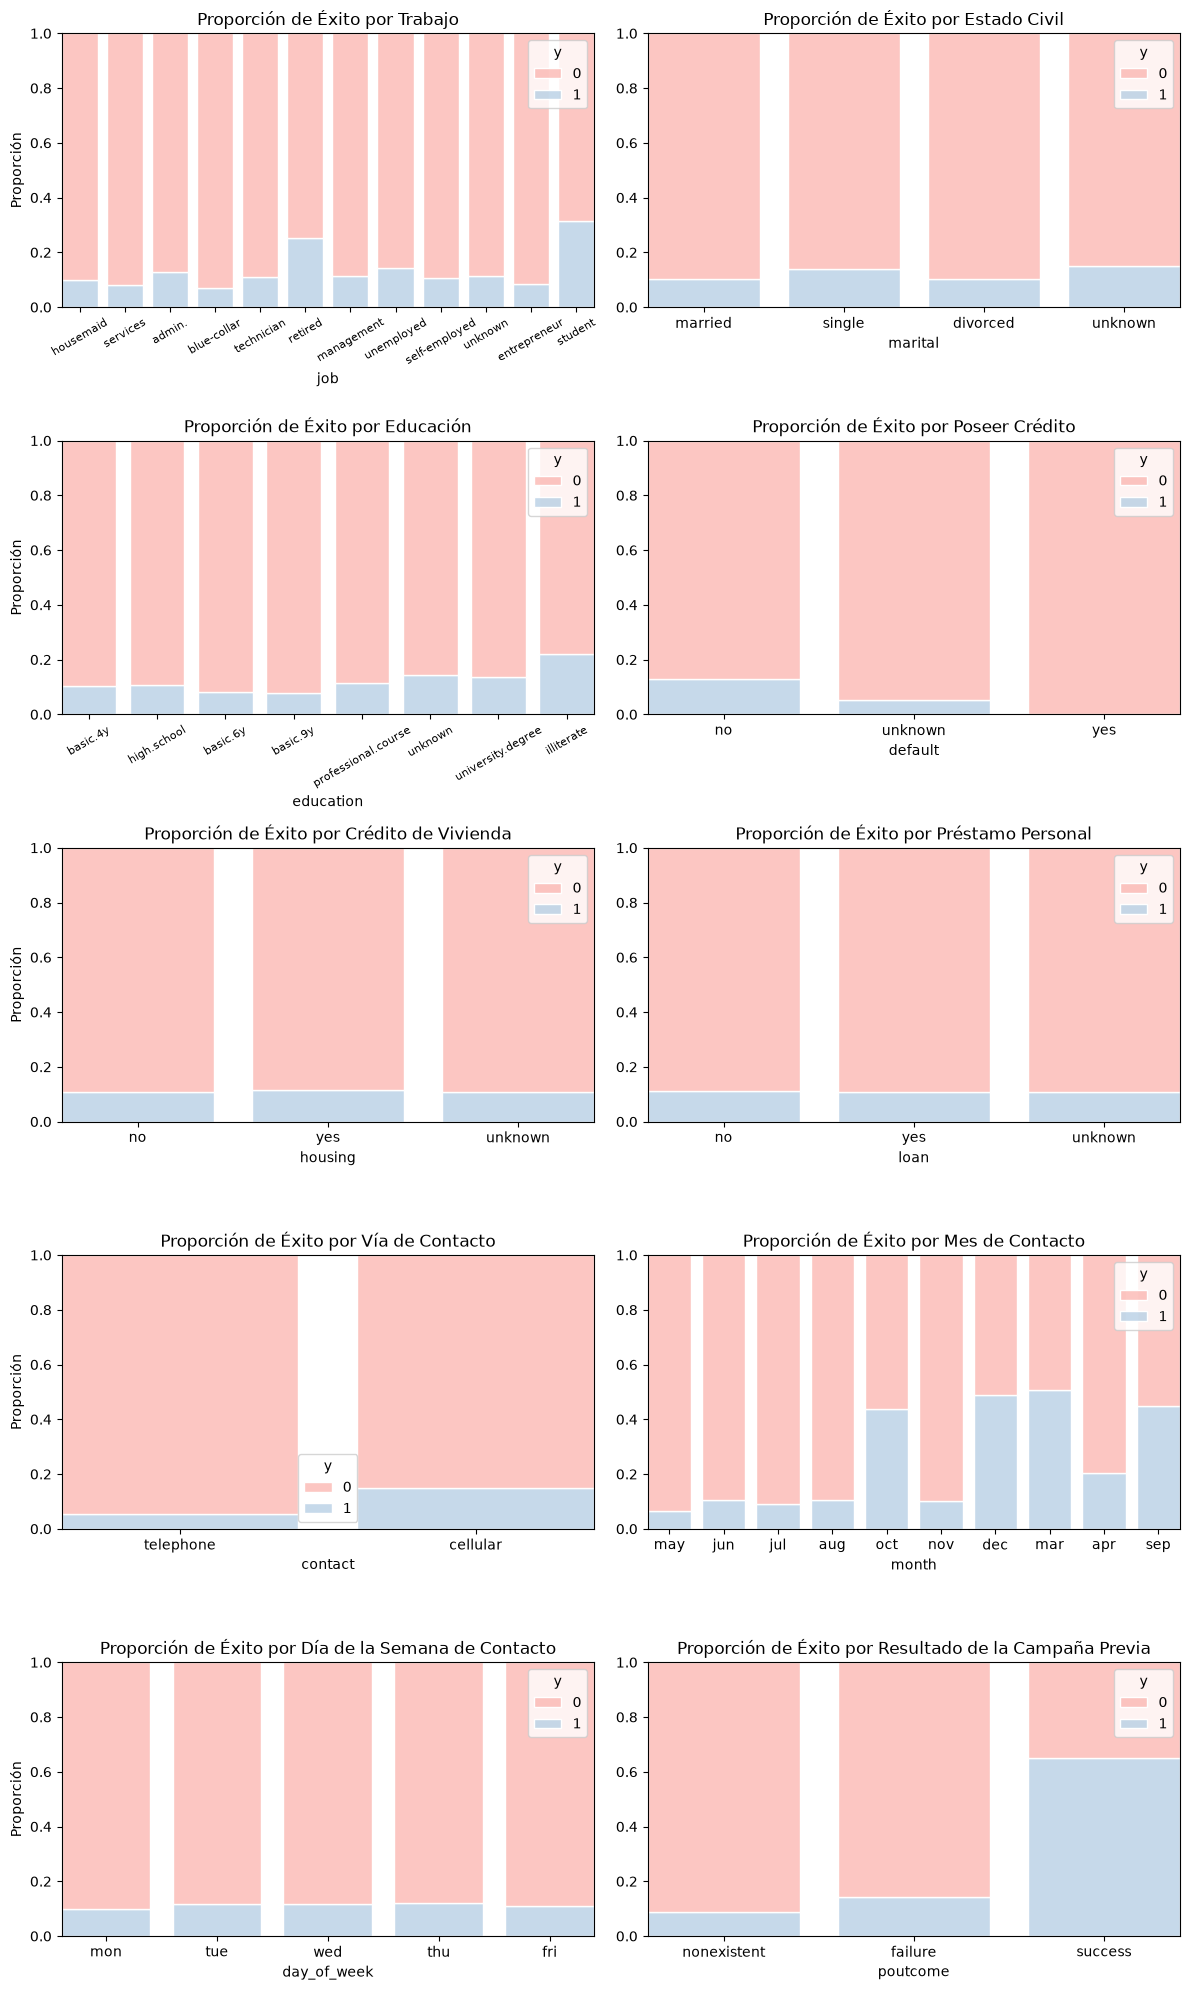

In [17]:
fig, axis = plt.subplots(5, 2, figsize = (12, 20))


#Visualización: proporción de éxito por trabajo
sns.histplot(ax=axis[0,0], data=df, x='job', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Trabajo")
axis[0,0].set(ylabel = "Proporción")
axis[0,0].tick_params(axis='x', rotation=30, labelsize=8)
#Visualización: proporción éxito por marital
sns.histplot(ax=axis[0,1], data=df, x='marital', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Estado Civil")
axis[0,1].set(ylabel = None)
#Visualización: proporción de éxito por educación
sns.histplot(ax=axis[1,0], data=df, x='education', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Educación")
axis[1,0].set(ylabel = "Proporción")
axis[1,0].tick_params(axis='x', rotation=30, labelsize=8)
#Visualización: proporción de éxito por poseer crédito
sns.histplot(ax=axis[1,1], data=df, x='default', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Poseer Crédito")
axis[1,1].set(ylabel = None)
#Visualización: proporción de éxito por crédito de vivienda
sns.histplot(ax=axis[2,0], data=df, x='housing', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Crédito de Vivienda")
axis[2,0].set(ylabel = "Proporción")
#Visualización: proporción de éxito por préstamo personal
sns.histplot(ax=axis[2,1], data=df, x='loan', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Préstamo Personal")
axis[2,1].set(ylabel = None)
#Visualización: proporción de éxito por vía de contacto
sns.histplot(ax=axis[3,0], data=df, x='contact', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Vía de Contacto")
axis[3,0].set(ylabel = "Proporción")
#Visualización: proporción de éxito por mes de contacto
sns.histplot(ax=axis[3,1], data=df, x='month', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Mes de Contacto")
axis[3,1].set(ylabel = None)
#Visualización: proporción de éxito por día de la semana de contacto
sns.histplot(ax=axis[4,0], data=df, x='day_of_week', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Día de la Semana de Contacto")
axis[4,0].set(ylabel = "Proporción")
#Visualización: proporción de éxito por resultado de la campaña previa
sns.histplot(ax=axis[4,1], data=df, x='poutcome', hue='y', multiple='fill', shrink=0.8, palette='Pastel1', edgecolor='white').set_title("Proporción de Éxito por Resultado de la Campaña Previa")
axis[4,1].set(ylabel = None)

plt.tight_layout()
plt.show()

El análisis de las tablas de contingencia y el test Chi-cuadrado nos muestran una fuerte asociación entre el Resultado de la Campaña Previa ("poutcome") del cliente y su Éxito ("y"), lo que nos indica que si un cliente ya aceptó una oferta en una campaña anterior, tiene una altísima probabilidad de volver a decir que si.

Por otro lado, podemos observar que hay meses en que la tasa de éxito es más alta que en otros, específicamente los meses de marzo ("mar"), septiembre ("sep"), octubre ("oct") y diciembre ("dic"). 

También se puede inferir que el tipo de contacto influye muchísimo, siendo muchísimo más efectivo contactar vía celular ("cellular") que vía teléfono fijo ("telephone").

Con respecto al trabajo ("job"), el gráfico nos muestra que los estudiantes ("student") y los jubilados ("retired") son las clases que más éxito de contratación tienen.

El estado civil ("marital") de los clientes nos indica que los solteros ("single") aceptan con mayor frecuenia que los casados ("married") o divociados ("divorced") 

Tener o no un préstamo personal o un crédito de vivienda no afecta la probabilidad de que el cliente contrate un producto. Asi mismo, el día de la semana en que contactan al cliente tampoco hace gran diferencia.

#### Númerico-Categórico

**Correlación únicamente entre variables numéricas (Pearson), para ver relaciones lineales entre continuas**

In [18]:
numericas.append("y")

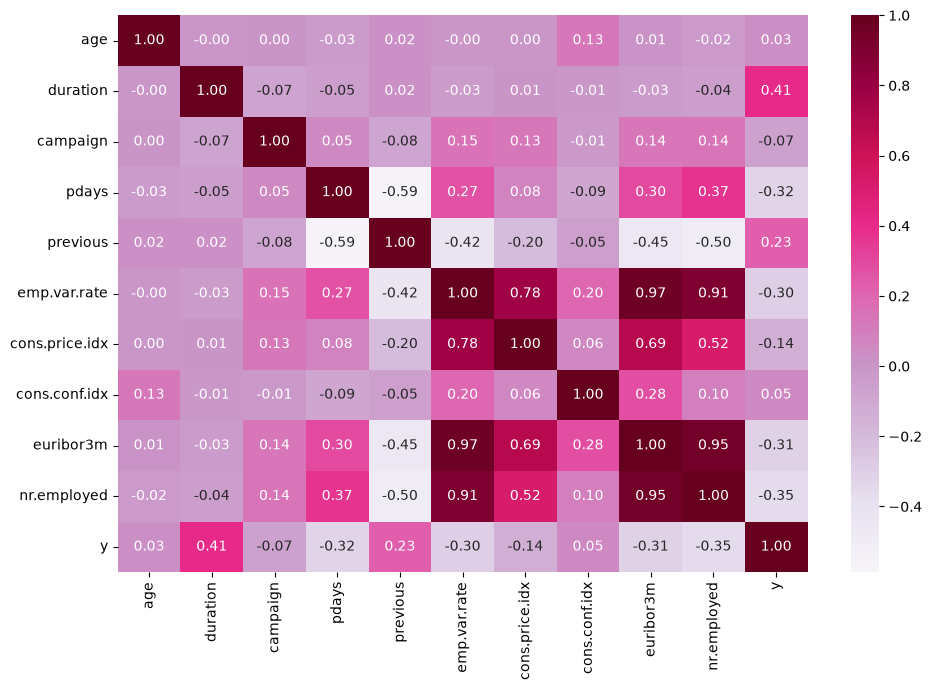

In [19]:
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(df[numericas].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax)
plt.tight_layout()
plt.show()

Del análisis de nuestra tabla de Pearson podemos observar multicolinealidad extremadamente alta entre "emp.var.rate-euribor3m", "emp.var.rate-nr.employed" y "euribor3m-nr.employed" que me lleva a decidir por una de ellas ya que estarían brindándonos información muy similar y nos afectaría en nuestro modelo. Ante esto, decido quedarme con **'nr.employed'** ya que es la que mejor correlación tiene con nuestra variable objetivo


In [20]:
df = df.drop(columns=['emp.var.rate', 'euribor3m'])


**Relación numérico–categórico mediante tasas/boxplots, sin usar Pearson con dummies**

,conversion_rate
job,
admin.,0.129667
blue-collar,0.068951
entrepreneur,0.085165
housemaid,0.100000
management,0.112175
retired,0.252619
self-employed,0.104856
services,0.081422
student,0.314286


,conversion_rate
marital,
divorced,0.103231
married,0.101561
single,0.140090
unknown,0.150000


,conversion_rate
education,
basic.4y,0.102490
basic.6y,0.082060
basic.9y,0.078246
high.school,0.108389
illiterate,0.222222
professional.course,0.113550
university.degree,0.137208
unknown,0.145087


,conversion_rate
default,
no,0.128803
unknown,0.051536
yes,0.000000


,conversion_rate
housing,
no,0.108783
unknown,0.108081
yes,0.116221


,conversion_rate
loan,
no,0.113413
unknown,0.108081
yes,0.109315


,conversion_rate
contact,
cellular,0.147389
telephone,0.052324


,conversion_rate
month,
apr,0.204865
aug,0.106056
dec,0.489011
jul,0.090389
jun,0.105115
mar,0.505495
may,0.064357
nov,0.101463
oct,0.439331


,conversion_rate
day_of_week,
fri,0.108101
mon,0.099507
thu,0.121142
tue,0.117858
wed,0.116671


,conversion_rate
poutcome,
failure,0.142286
nonexistent,0.088324
success,0.651129


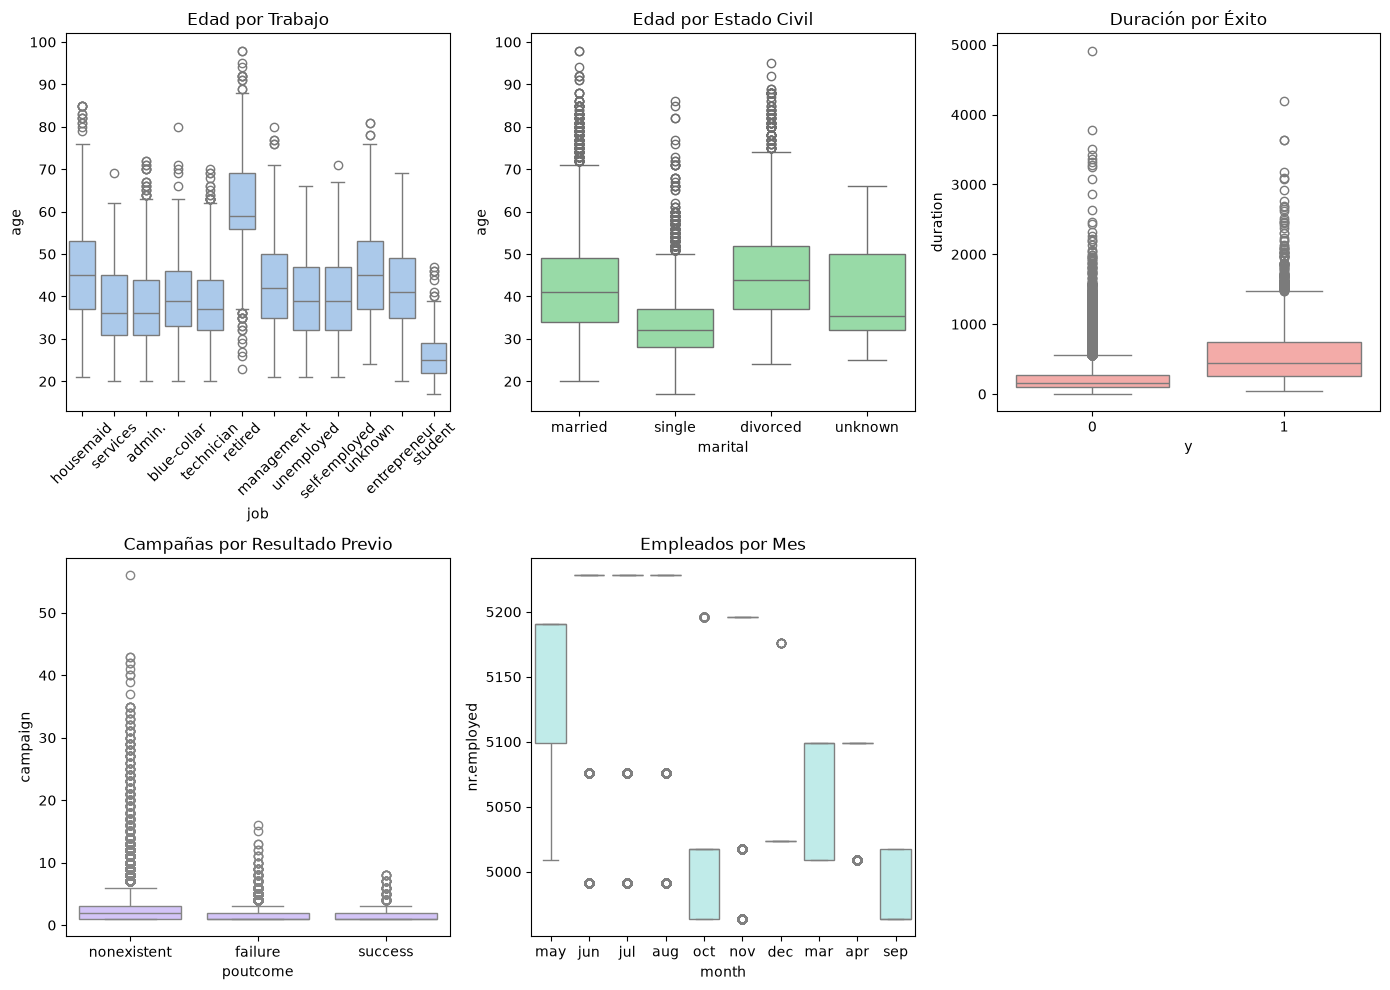

In [21]:
# Tasa de éxito por categoría
display(df.groupby("job")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("marital")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("education")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("default")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("housing")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("loan")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("contact")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("month")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("day_of_week")["y"].mean().rename("conversion_rate").to_frame())
display(df.groupby("poutcome")["y"].mean().rename("conversion_rate").to_frame())

# Boxplots de numéricas por categoría
fig, axes = plt.subplots(2, 3, figsize=(14,10))

sns.boxplot(ax=axes[0,0], data=df, x='job', y='age', color='#a1c9f4').tick_params(axis='x', rotation=45)
sns.boxplot(ax=axes[0,1], data=df, x="marital", y="age", color='#8de5a1')
sns.boxplot(ax=axes[0,2], data=df, x="y", y="duration", color='#ff9f9b')
sns.boxplot(ax=axes[1,0], data=df, x="poutcome", y="campaign", color='#d0bbff')
sns.boxplot(ax=axes[1,1], data=df, x="month", y="nr.employed", color='#b9f2f0')
axes[0,0].set_title("Edad por Trabajo"); axes[0,1].set_title("Edad por Estado Civil"); axes[0,2].set_title("Duración por Éxito"); axes[1,0].set_title("Campañas por Resultado Previo"); axes[1,1].set_title("Empleados por Mes")

fig.delaxes(axes[1,2])

plt.tight_layout()
plt.show()

**Pairplot**

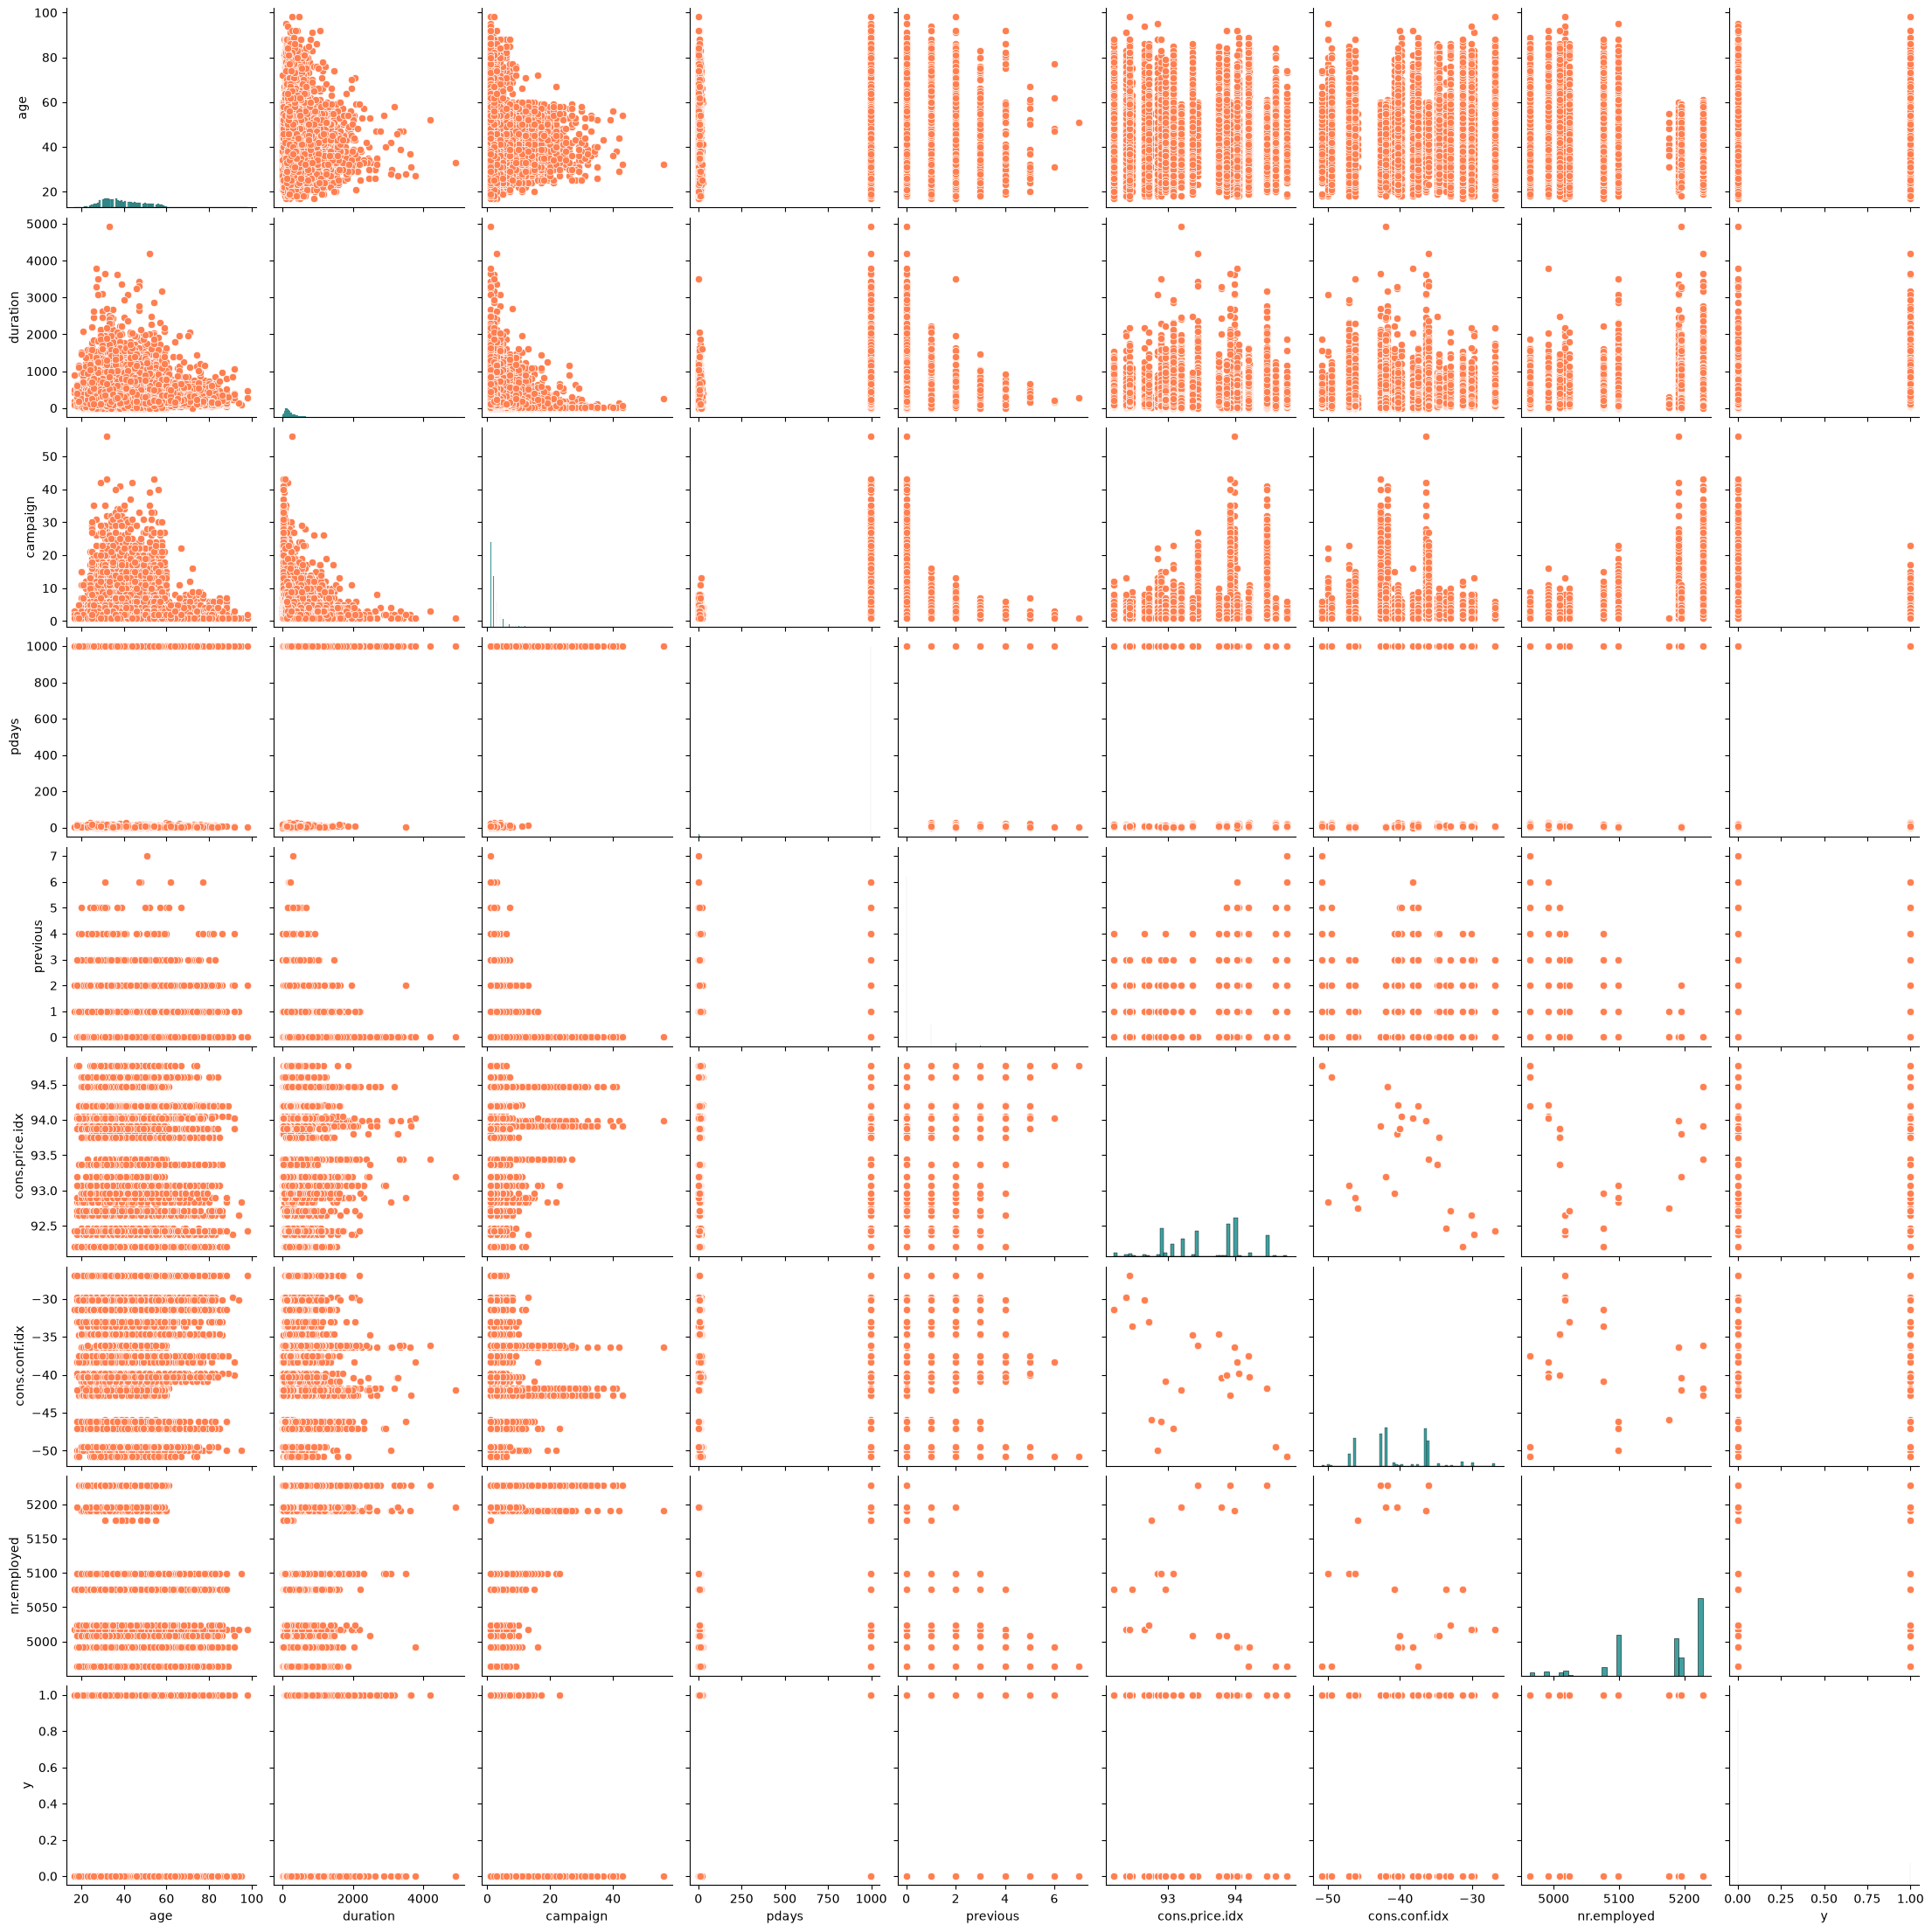

In [22]:
sns.pairplot(data = df, plot_kws={'color': 'coral'}, diag_kws={'color': 'teal'})
plt.show()

### Paso 5 EDA: Ingeniería de características

#### Análisis de Outliers

In [23]:
df.describe()

,age,duration,campaign,pdays,previous,cons.price.idx,cons.conf.idx,nr.employed,y
count,41176.00000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,962.464810,0.173013,93.575720,-40.502863,5167.034870,0.112663
std,10.42068,259.305321,2.770318,186.937102,0.494964,0.578839,4.627860,72.251364,0.316184
min,17.00000,0.000000,1.000000,0.000000,0.000000,92.201000,-50.800000,4963.600000,0.000000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,93.075000,-42.700000,5099.100000,0.000000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,93.749000,-41.800000,5191.000000,0.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,93.994000,-36.400000,5228.100000,0.000000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,94.767000,-26.900000,5228.100000,1.000000


In [24]:
for columna in categoricas:
    df[columna]=pd.factorize(df[columna])[0]
    
df.info()

<class 'pandas.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  int64  
 2   marital         41176 non-null  int64  
 3   education       41176 non-null  int64  
 4   default         41176 non-null  int64  
 5   housing         41176 non-null  int64  
 6   loan            41176 non-null  int64  
 7   contact         41176 non-null  int64  
 8   month           41176 non-null  int64  
 9   day_of_week     41176 non-null  int64  
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  int64  
 15  cons.price.idx  41176 non-null  float64
 16  cons.conf.idx   41176 non-null  float64
 17  nr.employed     41176 non-null  float64
 18  y 

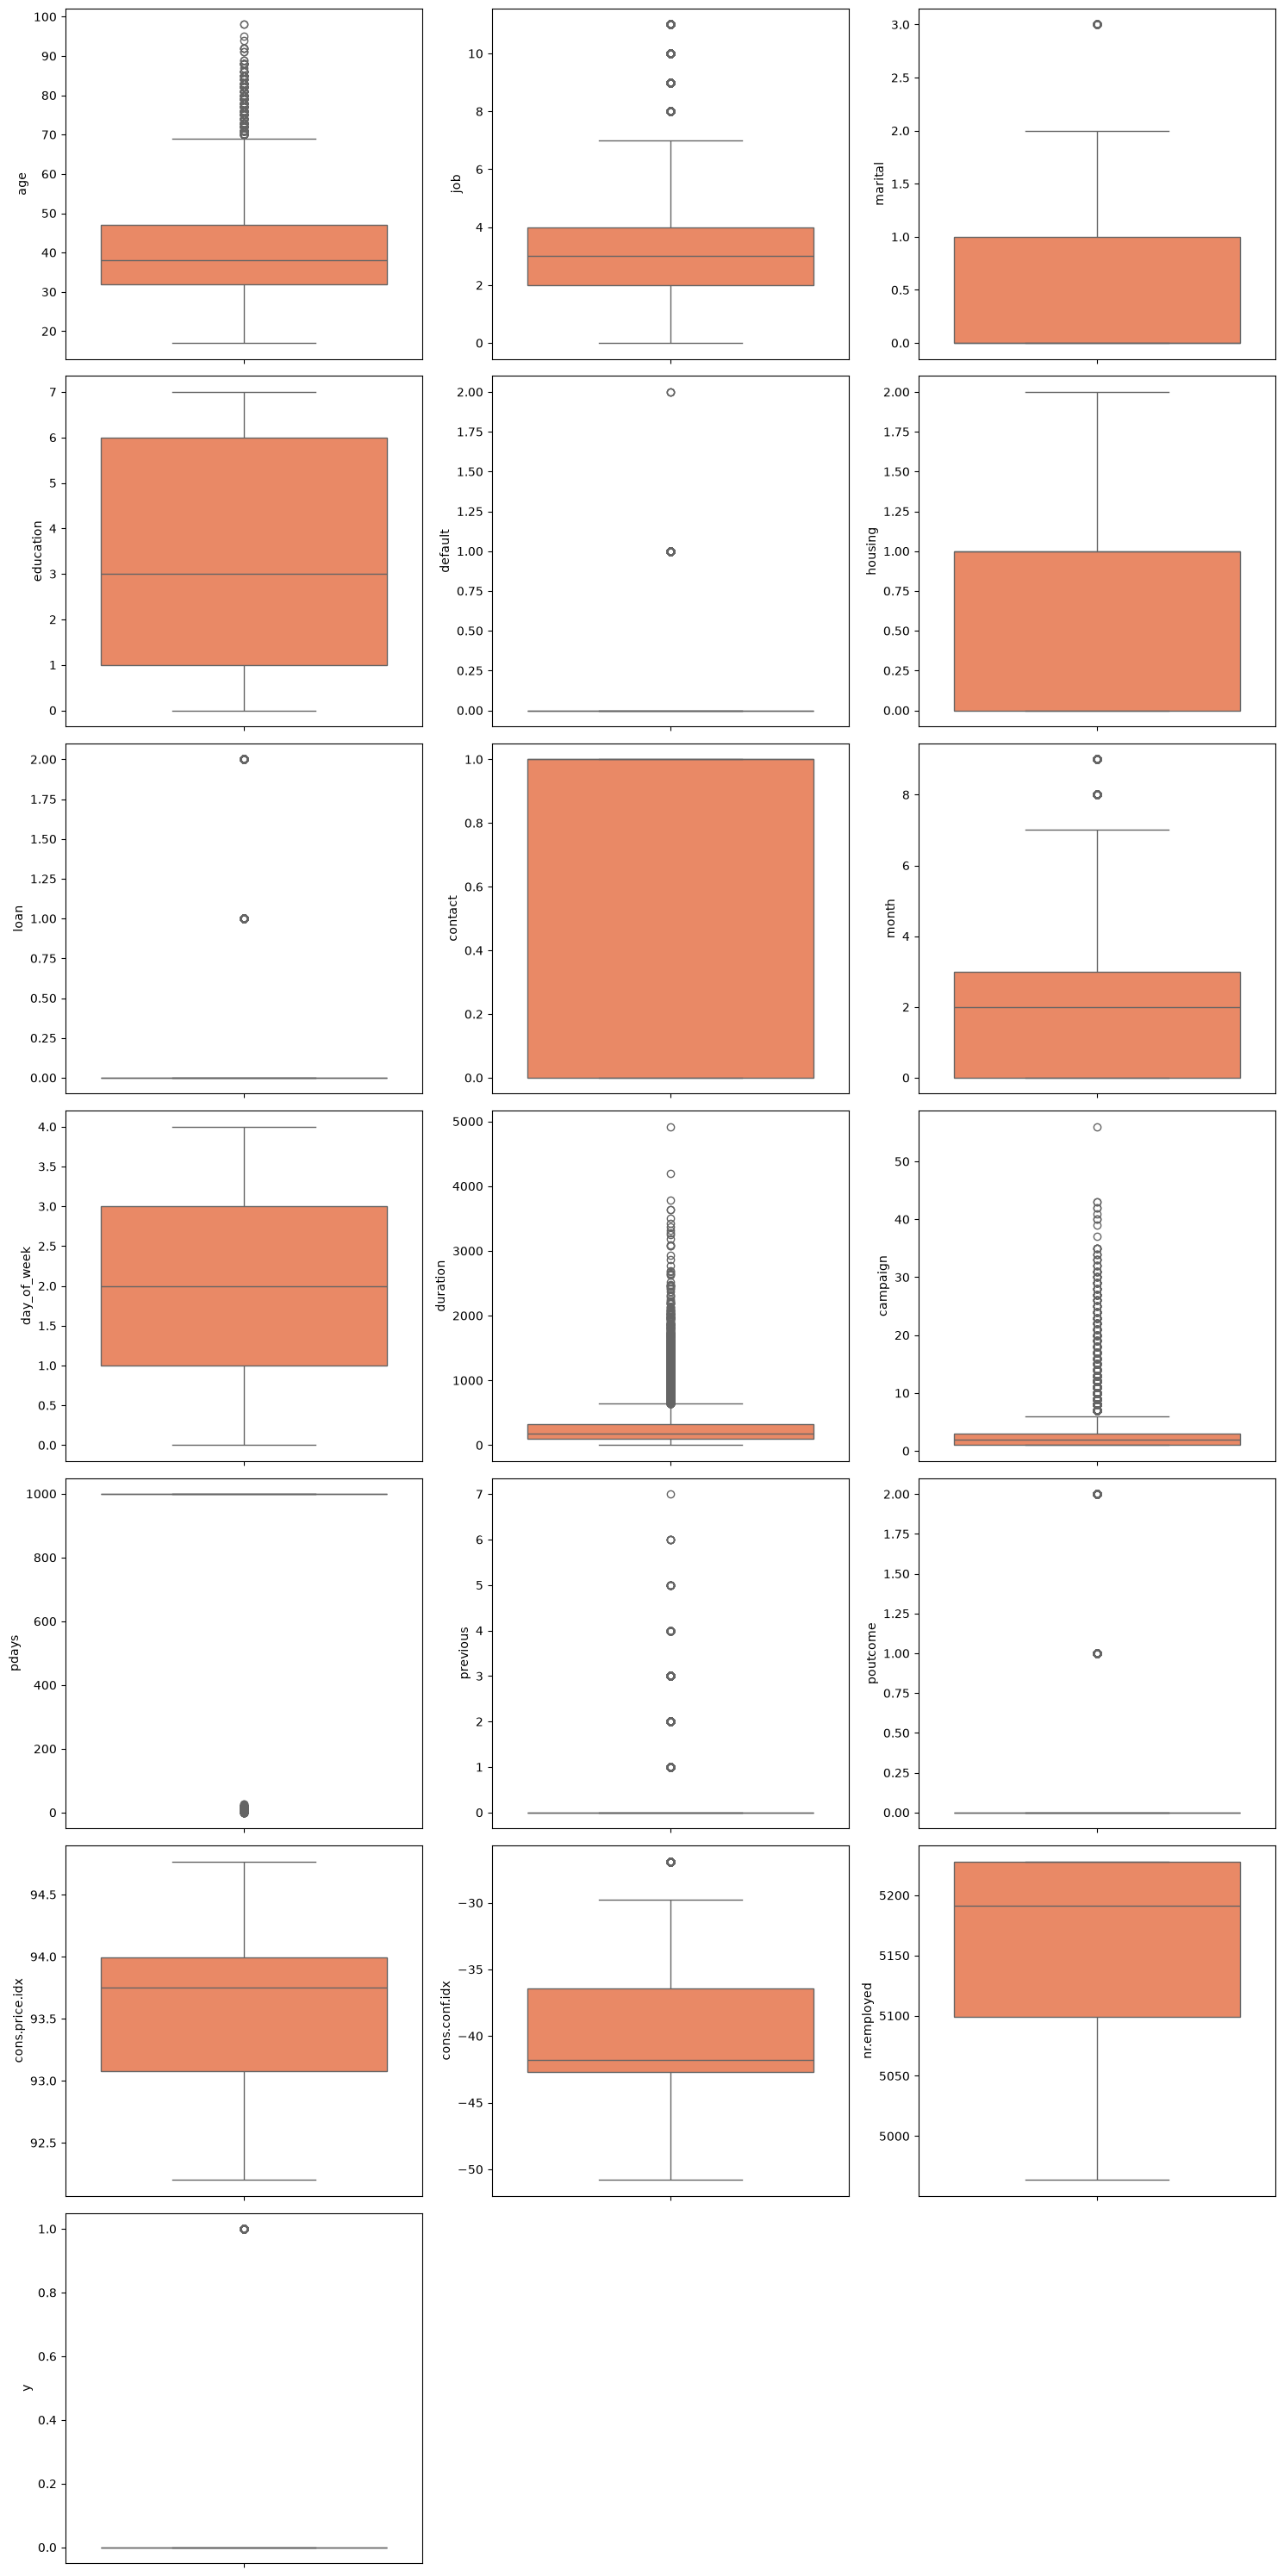

In [25]:
fig, axis = plt.subplots(7, 3, figsize = (15, 30))

sns.boxplot(ax = axis[0, 0], data = df, y = "age", color = 'coral')
sns.boxplot(ax = axis[0, 1], data = df, y = "job", color = 'coral')
sns.boxplot(ax = axis[0, 2], data = df, y = "marital", color = 'coral')
sns.boxplot(ax = axis[1, 0], data = df, y = "education", color = 'coral')
sns.boxplot(ax = axis[1, 1], data = df, y = "default", color = 'coral')
sns.boxplot(ax = axis[1, 2], data = df, y = "housing", color = 'coral')
sns.boxplot(ax = axis[2, 0], data = df, y = "loan", color = 'coral')
sns.boxplot(ax = axis[2, 1], data = df, y = "contact", color = 'coral')
sns.boxplot(ax = axis[2, 2], data = df, y = "month", color = 'coral')
sns.boxplot(ax = axis[3, 0], data = df, y = "day_of_week", color = 'coral')
sns.boxplot(ax = axis[3, 1], data = df, y = "duration", color = 'coral')
sns.boxplot(ax = axis[3, 2], data = df, y = "campaign", color = 'coral')
sns.boxplot(ax = axis[4, 0], data = df, y = "pdays", color = 'coral')
sns.boxplot(ax = axis[4, 1], data = df, y = "previous", color = 'coral')
sns.boxplot(ax = axis[4, 2], data = df, y = "poutcome", color = 'coral')
sns.boxplot(ax = axis[5, 0], data = df, y = "cons.price.idx", color = 'coral')
sns.boxplot(ax = axis[5, 1], data = df, y = "cons.conf.idx", color = 'coral')
sns.boxplot(ax = axis[5, 2], data = df, y = "nr.employed", color = 'coral')
sns.boxplot(ax = axis[6, 0], data = df, y = "y", color = 'coral')

fig.delaxes(axis[6, 1])
fig.delaxes(axis[6, 2])


plt.tight_layout()

plt.show()

No hay ningun outlier que amerite eliminar o reemplazar.

#### Análisis de valores faltantes

In [26]:
df.isnull().sum().sort_values(ascending=False)

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
cons.price.idx    0
cons.conf.idx     0
nr.employed       0
y                 0
dtype: int64

No hay valores faltantes

#### Inferencia de nuevas características

No se realizará fusiones de características ya que, por el tipo de variables e información que estas continen, no es un paso necesario para nosotros en este caso concreto. 

#### Separación en conjunto de train y test

In [27]:
X = df.drop(columns=['y'])
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

#### Escalado de valores

In [28]:
scaler = StandardScaler()
X_train_escalado = scaler.fit_transform(X_train)
X_test_escalado = scaler.transform(X_test)


X_train_escalado = pd.DataFrame(X_train_escalado, columns=X_train.columns, index=X_train.index)
X_test_escalado = pd.DataFrame(X_test_escalado, columns=X_test.columns, index=X_test.index)

In [29]:
X_train_escalado.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,nr.employed
12348,-1.058427,2.600348,-0.734095,-0.582336,-0.511455,0.788248,1.750366,-1.316322,-0.103815,1.433936,0.112453,0.152155,0.195697,-0.348601,-0.371649,0.589534,-0.470932,0.843413
8565,0.954767,-0.679177,0.698859,1.248416,-0.511455,-1.060840,-0.440002,-1.316322,-0.515428,0.014863,-0.305973,1.229538,0.195697,-0.348601,-0.371649,1.534740,-0.276368,0.843413
21424,-1.058427,-0.679177,0.698859,1.248416,-0.511455,-1.060840,-0.440002,0.759693,0.307797,-0.694674,-0.596546,0.511282,0.195697,-0.348601,-0.371649,-0.229530,0.955866,0.843413
3316,-0.483229,-0.679177,0.698859,1.248416,-0.511455,-1.060840,-0.440002,-1.316322,-0.927040,0.724399,-0.472568,-0.566100,0.195697,-0.348601,-0.371649,0.720860,0.891011,0.330793
33246,-0.003897,-0.269237,0.698859,-1.040024,1.953044,-1.060840,-0.440002,0.759693,-0.927040,-0.694674,0.623862,-0.566100,0.195697,-0.348601,-0.371649,-1.181648,-1.227566,-0.939011


### Paso 6: Selección de características

In [30]:
k_features = 18
selector = SelectKBest(score_func=f_classif, k=k_features)

X_train_seleccionado_array = selector.fit_transform(X_train, y_train)

X_test_seleccionado_array = selector.transform(X_test)

selected_mask = selector.get_support()
columnas_seleccionadas = X_train.columns[selected_mask]
puntaje_columnas = selector.scores_[selected_mask]

X_train_seleccionado = pd.DataFrame(X_train_seleccionado_array, columns=columnas_seleccionadas, index=X_train.index)
X_test_seleccionado = pd.DataFrame(X_test_seleccionado_array, columns=columnas_seleccionadas, index=X_test.index)

scores_df = pd.DataFrame(
    {"Feature": columnas_seleccionadas, "Score": puntaje_columnas}
).sort_values(by="Score", ascending=False)

print("Mejores características seleccionadas:")
print(scores_df)

Mejores características seleccionadas:
           Feature        Score
10        duration  6559.317831
17     nr.employed  4781.144602
12           pdays  3862.822950
14        poutcome  2544.070992
13        previous  1789.196241
8            month  1174.884879
7          contact   688.613958
15  cons.price.idx   615.408299
4          default   308.814989
11        campaign   143.899093
16   cons.conf.idx   113.594799
1              job    96.473700
3        education    66.081683
0              age    35.067374
2          marital    29.661740
9      day_of_week     4.560839
5          housing     2.796500
6             loan     1.398925


Pese a que la variable "duration" tiene el puntaje más alto, la eliminaré debido a que no se puede conocer la duración de la llamada antes de realizarla. Con respecto a las demás, me quedaré solo con las que tengan un puntaje mayor a 300.

In [31]:
X_train_escalado = X_train_escalado.drop(columns=['duration'])
X_test_escalado = X_test_escalado.drop(columns=['duration'])

In [32]:
k_features = 8
selector = SelectKBest(score_func=f_classif, k=k_features)

X_train_seleccionado_array = selector.fit_transform(X_train_escalado, y_train)

X_test_seleccionado_array = selector.transform(X_test_escalado)

selected_mask = selector.get_support()
columnas_seleccionadas = X_train_escalado.columns[selected_mask]
puntaje_columnas = selector.scores_[selected_mask]

X_train_seleccionado = pd.DataFrame(X_train_seleccionado_array, columns=columnas_seleccionadas, index=X_train_escalado.index)
X_test_seleccionado = pd.DataFrame(X_test_seleccionado_array, columns=columnas_seleccionadas, index=X_test_escalado.index)

scores_df = pd.DataFrame(
    {"Feature": columnas_seleccionadas, "Score": puntaje_columnas}
).sort_values(by="Score", ascending=False)

print("Mejores características seleccionadas:")
print(scores_df)

Mejores características seleccionadas:
          Feature        Score
7     nr.employed  4781.144619
3           pdays  3862.822950
5        poutcome  2544.070992
4        previous  1789.196241
2           month  1174.884879
1         contact   688.613958
6  cons.price.idx   615.408299
0         default   308.814989


In [33]:
X_train_seleccionado['y'] = list(y_train)
X_test_seleccionado['y'] = list(y_test)

X_train_seleccionado.to_csv('../data/processed/train_limpio.csv', index= False)
X_test_seleccionado.to_csv('../data/processed/test_limpio.csv', index= False)

### Fin del EDA

## Paso 3: Construye un modelo de regresión logística

In [34]:
X_train_final = X_train_seleccionado.drop(columns=['y'])
X_test_final = X_test_seleccionado.drop(columns=['y'])
y_train_final = X_train_seleccionado['y']
y_test_final = X_test_seleccionado['y']

In [38]:
model = LogisticRegression()
model.fit(X_train_final, y_train_final)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [39]:
y_pred = model.predict(X_test_final)
y_pred

array([0, 0, 1, ..., 0, 0, 0], shape=(8236,))

In [40]:
accuracy_score(y_test_final, y_pred)

0.8954589606605148

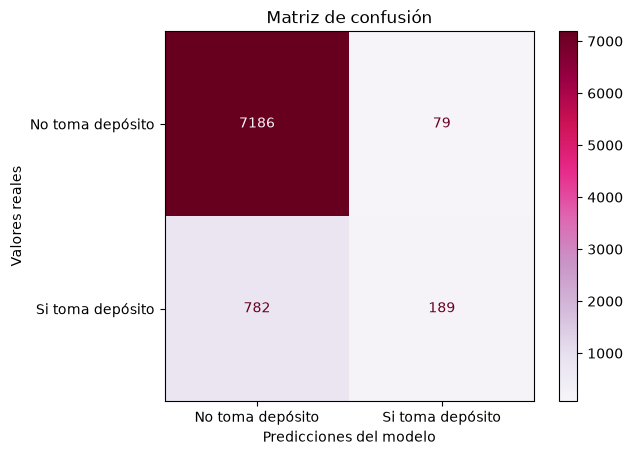

In [42]:
cm = confusion_matrix(y_test_final, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No toma depósito', 'Si toma depósito'])

disp.plot(cmap=plt.cm.PuRd)

plt.xlabel("Predicciones del modelo")
plt.ylabel("Valores reales")
plt.title("Matriz de confusión")
plt.show()